# ModelForge AI — Dataset Inspection

**Purpose:** Inspect the existing train / validation / test dataset before deciding whether to keep its split or create a new 70/15/15 split.

- This notebook is read-only.
- It does not move, rename, delete, rewrite, or crop any dataset files.
- It supports common YOLO layouts such as `train/images + train/labels`, `images/train + labels/train`, and class-folder image datasets.

## 1. Configure the dataset path

The copied dataset should be here:

`E:\ModelForge-AI\data\raw\waste_dataset`

If your dataset is nested one extra folder deep, update `DATASET_ROOT` to the folder that directly contains `train`, `valid`/`validation`, and `test`, or the `images` and `labels` folders.

In [1]:
from pathlib import Path
import os, re, json, hashlib, warnings
from collections import Counter, defaultdict

DATASET_ROOT = Path(r"E:\ModelForge-AI\data\raw\waste_dataset")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SPLIT_ALIASES = {
    "train": ["train", "training"],
    "val": ["val", "valid", "validation", "validate"],
    "test": ["test", "testing"],
}

print("Dataset exists:", DATASET_ROOT.exists())
print("Dataset path:", DATASET_ROOT)
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_ROOT}")

Dataset exists: True
Dataset path: E:\ModelForge-AI\data\raw\waste_dataset


## 2. Inspect the folder structure

In [2]:
def show_tree(root: Path, max_depth=4, max_items=80):
    root = root.resolve()
    shown = 0
    for current, dirs, files in os.walk(root):
        current_path = Path(current)
        depth = len(current_path.relative_to(root).parts)
        if depth >= max_depth:
            dirs[:] = []
        indent = "  " * depth
        print(f"{indent}{current_path.name}/")
        for filename in sorted(files)[:max(0, max_items - shown)]:
            print(f"{indent}  {filename}")
            shown += 1
        if shown >= max_items:
            print("... output limited ...")
            break

show_tree(DATASET_ROOT)

waste_dataset/
  data.yaml
  images/
    test/
      107_jpg.rf.c33c46e1bf4fabdbe7673ce826493f2e.jpg
      126_jpg.rf.d24c502d9f5415c11524ed22003a7760.jpg
      130_jpeg_jpg.rf.d8e8c1255972946e93286cabf65fea28.jpg
      152_jpeg_jpg.rf.4458ceb8ac658e02c6869ac73de4393e.jpg
      160_jpg.rf.a3de6ae9f3c07003ba8632175e96139b.jpg
      169_jpeg_jpg.rf.88414ec43ebe43ff28e667bf4d9af56b.jpg
      195_jpg.rf.e38c215fd9f29158253e0ec686ece322.jpg
      1J5CX0G1UCIV_jpg.rf.01c71839a155477a56c0787a958358f1.jpg
      201_jpg.rf.697ad15c3af567b3f28e52687f2dab77.jpg
      20220205_150318_jpg.rf.abac673bdc0cc7c774c905465987b02b.jpg
      20220205_150655_jpg.rf.340ea9b1c376a4ec9c1be25af6d13c0c.jpg
      20220205_150821_jpg.rf.2bf4ee5aa477527311691cda037d5aa1.jpg
      20220216_175140_jpg.rf.643ca7dd3a88b9bda06c0a743cc67bc2.jpg
      20220216_181346_jpg.rf.7ddd9455d4ee3b41b5a8106119da4a57.jpg
      20220216_181401_jpg.rf.de2a79728445f05d48f7627277089eda.jpg
      20231217_150011_jpg.rf.7eec98d17646e630e5

## 3. Find existing split folders and count images

This detects split names such as `train`, `valid`, `validation`, and `test`, including layouts where splits are under an `images` directory.

In [3]:
def find_split_dirs(root: Path):
    found = {}
    for canonical, aliases in SPLIT_ALIASES.items():
        candidates = []
        for p in root.rglob("*"):
            if p.is_dir() and p.name.lower() in aliases:
                # Prefer a split folder that contains images directly or below it.
                has_images = any(
                    f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
                    for f in p.rglob("*")
                )
                if has_images:
                    candidates.append(p)
        if candidates:
            # Prefer the shallowest matching directory to avoid counting nested duplicates.
            candidates.sort(key=lambda x: (len(x.relative_to(root).parts), str(x).lower()))
            found[canonical] = candidates[0]
    return found

split_dirs = find_split_dirs(DATASET_ROOT)
print("Detected split directories:")
for split, folder in split_dirs.items():
    print(f"{split:>5}: {folder.relative_to(DATASET_ROOT)}")

if not split_dirs:
    print("No train/validation/test split folders detected. Review the folder tree above.")

def images_under(folder: Path):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

split_images = {split: images_under(folder) for split, folder in split_dirs.items()}

print("\\nImage counts:")
for split in ["train", "val", "test"]:
    count = len(split_images.get(split, []))
    print(f"{split:>5}: {count:>6,} images")

total_images = sum(len(v) for v in split_images.values())
print(f" total: {total_images:>6,} images")

print("\\nCurrent split percentages:")
for split in ["train", "val", "test"]:
    count = len(split_images.get(split, []))
    pct = (100 * count / total_images) if total_images else 0
    print(f"{split:>5}: {pct:6.2f}%")

Detected split directories:
train: images\train
  val: images\val
 test: images\test
\nImage counts:
train:  1,462 images
  val:    432 images
 test:    183 images
 total:  2,077 images
\nCurrent split percentages:
train:  70.39%
  val:  20.80%
 test:   8.81%


## 4. Find YAML configuration and read class names

YOLO datasets commonly include `data.yaml` or `data.yml`. This cell reads the YAML if PyYAML is installed. It does not modify it.

In [4]:
yaml_files = sorted(
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {".yaml", ".yml"}
)
print("YAML files:")
for p in yaml_files:
    print("-", p.relative_to(DATASET_ROOT))

class_names = None
if yaml_files:
    selected_yaml = yaml_files[0]
    print("\\nReading:", selected_yaml)
    try:
        import yaml
        with selected_yaml.open("r", encoding="utf-8") as f:
            yaml_data = yaml.safe_load(f)
        print(json.dumps(yaml_data, indent=2, ensure_ascii=False, default=str))
        names = yaml_data.get("names") if isinstance(yaml_data, dict) else None
        if isinstance(names, dict):
            class_names = {int(k): str(v) for k, v in names.items()}
        elif isinstance(names, list):
            class_names = {i: str(v) for i, v in enumerate(names)}
    except ImportError:
        print("PyYAML is not installed. Install it with: %pip install pyyaml")
    except Exception as e:
        print("Could not parse YAML:", repr(e))
else:
    print("No YAML file found.")

print("\\nDetected class mapping:", class_names)

YAML files:
- data.yaml
\nReading: E:\ModelForge-AI\data\raw\waste_dataset\data.yaml
{
  "path": "E:/Waste Detection System PITB/dataset",
  "train": "images/train",
  "val": "images/val",
  "test": "images/test",
  "names": {
    "0": "Plastic Bottle",
    "1": "Paper",
    "2": "Can",
    "3": "Plastic Bag"
  }
}
\nDetected class mapping: {0: 'Plastic Bottle', 1: 'Paper', 2: 'Can', 3: 'Plastic Bag'}


## 5. Inspect YOLO annotation files

For YOLO detection labels, each non-empty line should contain:

`class_id x_center y_center width height`

The coordinates should be normalized between 0 and 1. This cell reports label-file counts, object counts per class, malformed lines, and images without a matching label file. It also supports either `split/images` + `split/labels` or `images/split` + `labels/split`.

In [5]:
def locate_label_dir(split_name: str, split_dir: Path):
    # Typical: dataset/train/images -> dataset/train/labels
    if split_dir.name.lower() == "images" and split_dir.parent.exists():
        sibling = split_dir.parent / "labels"
        if sibling.is_dir():
            return sibling
    # Typical: dataset/images/train -> dataset/labels/train
    parts = split_dir.parts
    if "images" in [x.lower() for x in parts]:
        idx = [x.lower() for x in parts].index("images")
        candidate = Path(*parts[:idx], "labels", *parts[idx+1:])
        if candidate.is_dir():
            return candidate
    # Typical: dataset/train with images and labels subfolders
    sibling = split_dir / "labels"
    if sibling.is_dir():
        return sibling
    # Search likely labels folder matching split
    for p in DATASET_ROOT.rglob("labels"):
        if p.is_dir() and split_name in p.as_posix().lower():
            return p
    return None

def image_to_label_path(image_path: Path, split_dir: Path, label_dir: Path):
    rel = None
    try:
        # If split_dir itself is .../images, preserve path relative to it.
        rel = image_path.relative_to(split_dir)
    except ValueError:
        pass
    if rel is None:
        # If the image is inside a nested images folder, use path relative to that folder.
        image_roots = [p for p in image_path.parents if p.name.lower() == "images"]
        if image_roots:
            rel = image_path.relative_to(image_roots[0])
        else:
            rel = Path(image_path.name)
    return (label_dir / rel).with_suffix(".txt")

label_report = {}
for split, imgs in split_images.items():
    split_dir = split_dirs[split]
    label_dir = locate_label_dir(split, split_dir)
    if label_dir is None:
        print(f"{split}: no matching labels directory detected.")
        label_report[split] = {"label_dir": None, "label_files": 0, "objects": Counter(), "malformed": 0, "missing_labels": len(imgs)}
        continue

    label_files = sorted(label_dir.rglob("*.txt"))
    objects = Counter()
    malformed = 0
    missing_labels = []
    for img in imgs:
        label_path = image_to_label_path(img, split_dir, label_dir)
        if not label_path.exists():
            missing_labels.append(img)
            continue
        try:
            lines = label_path.read_text(encoding="utf-8", errors="replace").splitlines()
        except Exception:
            malformed += 1
            continue
        for line in lines:
            line = line.strip()
            if not line:
                continue
            parts = re.split(r"\s+", line)
            if len(parts) != 5:
                malformed += 1
                continue
            try:
                cls = int(float(parts[0]))
                coords = [float(x) for x in parts[1:]]
                if not all(0 <= x <= 1 for x in coords):
                    malformed += 1
                    continue
                objects[cls] += 1
            except Exception:
                malformed += 1

    label_report[split] = {
        "label_dir": label_dir,
        "label_files": len(label_files),
        "objects": objects,
        "malformed": malformed,
        "missing_labels": len(missing_labels),
    }

    print(f"\\n{split.upper()} — labels: {label_dir}")
    print("Label files:", len(label_files))
    print("Images without matching label:", len(missing_labels))
    print("Malformed annotation lines:", malformed)
    print("Object counts by class ID:", dict(sorted(objects.items())))

print("\\nClass ID names:")
if class_names:
    for class_id, name in class_names.items():
        print(f"{class_id}: {name}")
else:
    print("Class names not identified from YAML; inspect the annotation IDs and confirm their meaning.")

\nTRAIN — labels: E:\ModelForge-AI\data\raw\waste_dataset\labels\train
Label files: 1462
Images without matching label: 0
Malformed annotation lines: 0
Object counts by class ID: {0: 869, 1: 468, 2: 806, 3: 749}
\nVAL — labels: E:\ModelForge-AI\data\raw\waste_dataset\labels\val
Label files: 432
Images without matching label: 0
Malformed annotation lines: 0
Object counts by class ID: {0: 251, 1: 194, 2: 212, 3: 282}
\nTEST — labels: E:\ModelForge-AI\data\raw\waste_dataset\labels\test
Label files: 183
Images without matching label: 0
Malformed annotation lines: 0
Object counts by class ID: {0: 93, 1: 71, 2: 65, 3: 133}
\nClass ID names:
0: Plastic Bottle
1: Paper
2: Can
3: Plastic Bag


## 6. Check image readability and image dimensions

This attempts to open each image with Pillow and reports unreadable files. It also summarizes common image dimensions. This is a read-only check.

In [6]:
try:
    from PIL import Image
except ImportError:
    raise ImportError("Pillow is required. Run: %pip install pillow")

image_quality = {}
for split, imgs in split_images.items():
    bad = []
    dimensions = Counter()
    for p in imgs:
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                dimensions[im.size] += 1
        except Exception as e:
            bad.append((p, str(e)))
    image_quality[split] = {"bad": bad, "dimensions": dimensions}
    print(f"\\n{split.upper()}: readable {len(imgs) - len(bad)}/{len(imgs)}")
    print("Unreadable:", len(bad))
    print("Most common dimensions:")
    for size, count in dimensions.most_common(10):
        print(f"  {size}: {count}")
    for p, err in bad[:10]:
        print("  BAD:", p, "|", err)

\nTRAIN: readable 1462/1462
Unreadable: 0
Most common dimensions:
  (4624, 3468): 403
  (512, 384): 243
  (416, 416): 115
  (4032, 3024): 80
  (1080, 1920): 58
  (1536, 2048): 26
  (500, 375): 22
  (4000, 3000): 19
  (500, 500): 13
  (600, 600): 11
\nVAL: readable 432/432
Unreadable: 0
Most common dimensions:
  (4624, 3468): 92
  (4032, 3024): 85
  (512, 384): 61
  (416, 416): 37
  (1080, 1920): 13
  (3024, 4032): 6
  (500, 375): 5
  (4000, 3000): 5
  (1536, 2048): 4
  (1157, 2048): 4
\nTEST: readable 183/183
Unreadable: 0
Most common dimensions:
  (4032, 3024): 34
  (4624, 3468): 25
  (512, 384): 16
  (416, 416): 9
  (1536, 2048): 6
  (1920, 1080): 4
  (1080, 1920): 3
  (512, 512): 3
  (1157, 2048): 3
  (2048, 1536): 3


## 7. Check whether the same image appears in multiple splits

This uses SHA-256 hashes to detect exact duplicate files across train, validation, and test. Hashing can take a little time for a large dataset, but it does not change any files.

In [7]:
hash_to_splits = defaultdict(set)
hash_to_paths = defaultdict(list)

for split, imgs in split_images.items():
    for p in imgs:
        try:
            h = hashlib.sha256()
            with p.open("rb") as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b""):
                    h.update(chunk)
            digest = h.hexdigest()
            hash_to_splits[digest].add(split)
            hash_to_paths[digest].append(p)
        except Exception as e:
            print("Hash failed:", p, repr(e))

cross_split_duplicates = {
    digest: paths
    for digest, paths in hash_to_paths.items()
    if len(hash_to_splits[digest]) > 1
}

print("Exact duplicate groups spanning multiple splits:", len(cross_split_duplicates))
for digest, paths in list(cross_split_duplicates.items())[:20]:
    print("\\nSHA256:", digest[:16], "...")
    for p in paths:
        print(" ", p.relative_to(DATASET_ROOT))

Exact duplicate groups spanning multiple splits: 0


## 8. Visual sample grid

This displays a few images from each detected split. For a YOLO dataset, this displays the original full images; it does not crop or alter them.

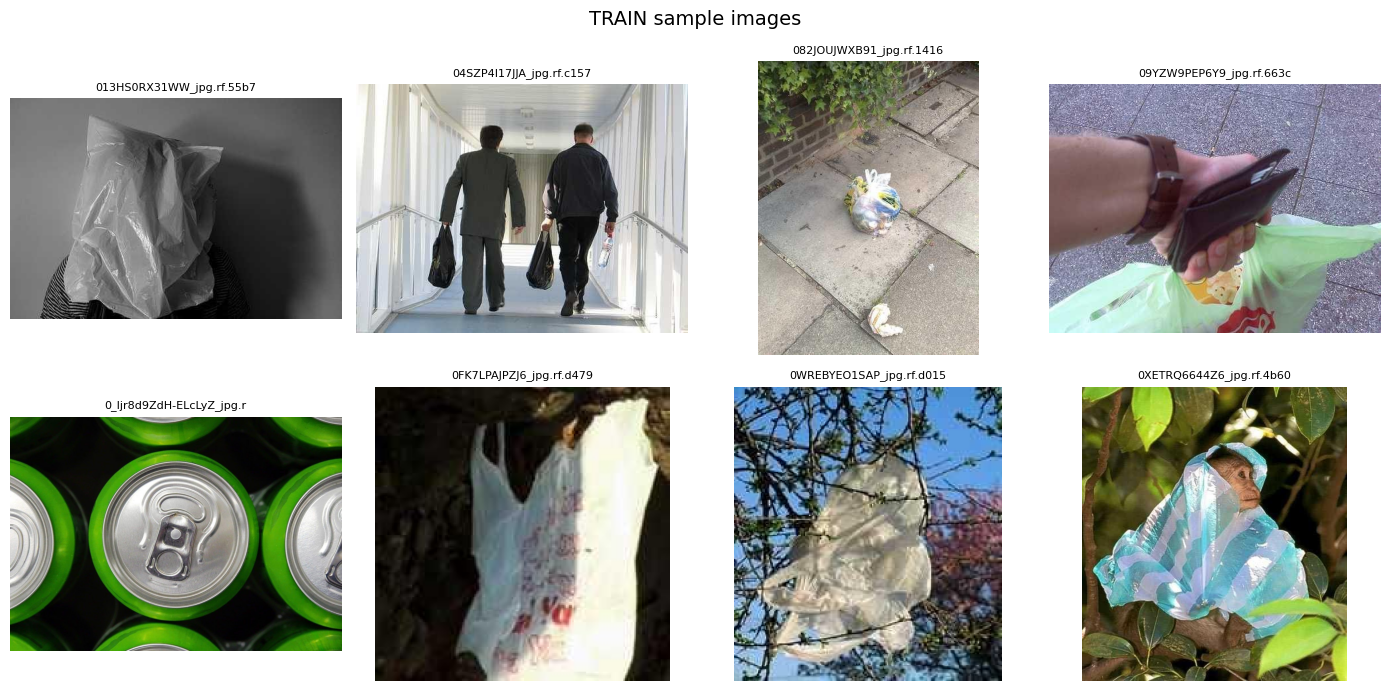

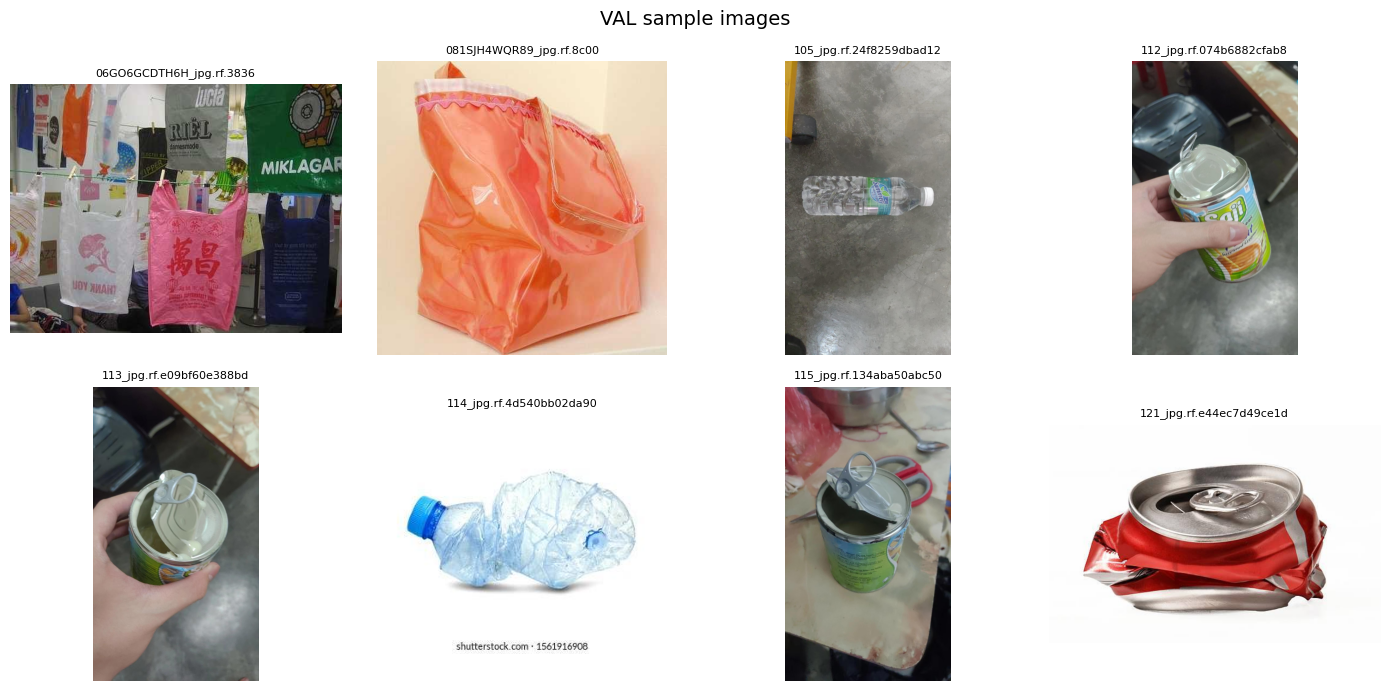

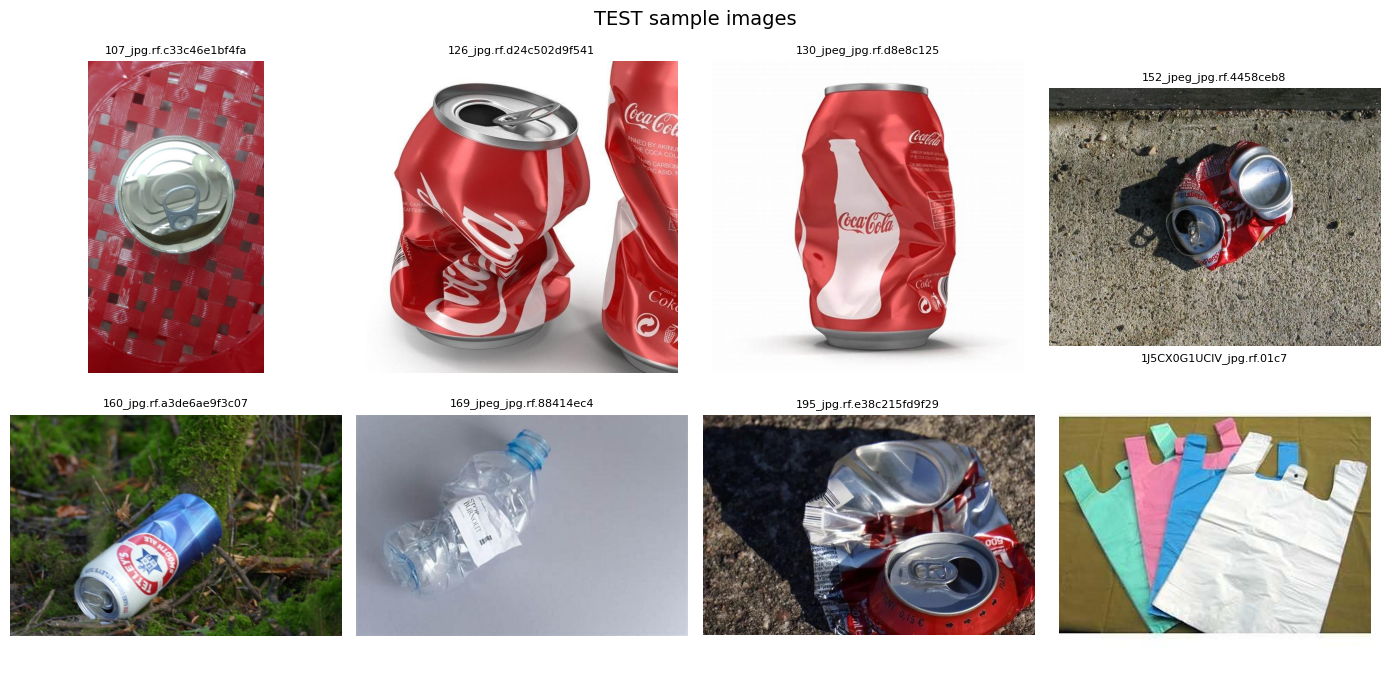

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

for split in ["train", "val", "test"]:
    imgs = split_images.get(split, [])
    if not imgs:
        continue
    sample = imgs[:8]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    fig.suptitle(f"{split.upper()} sample images", fontsize=14)
    for ax, p in zip(axes.flat, sample):
        try:
            with Image.open(p) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(p.name[:24], fontsize=8)
        except Exception:
            ax.set_title("Unreadable image")
        ax.axis("off")
    for ax in axes.flat[len(sample):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Final inspection summary and target ratio comparison

The target ratio is 70% train / 15% validation / 15% test. This section reports the current split and flags missing splits or large deviations. A ratio mismatch alone does not prove that the dataset must be changed; class balance and leakage matter too.

In [9]:
target = {"train": 0.70, "val": 0.15, "test": 0.15}
summary_rows = []
for split in ["train", "val", "test"]:
    n = len(split_images.get(split, []))
    pct = n / total_images if total_images else 0
    summary_rows.append({
        "split": split,
        "images": n,
        "actual_percent": round(pct * 100, 2),
        "target_percent": target[split] * 100,
        "difference_percentage_points": round((pct - target[split]) * 100, 2),
    })

try:
    import pandas as pd
    display(pd.DataFrame(summary_rows))
except ImportError:
    for row in summary_rows:
        print(row)

print("\\nDataset totals")
print("Total images:", total_images)
print("Detected splits:", list(split_dirs.keys()))
print("Class mapping:", class_names)
print("Cross-split exact duplicate groups:", len(cross_split_duplicates))

print("\\nImportant decision notes:")
print("- Keep the current split if it is valid, class-balanced enough, and leakage-free.")
print("- If changing ratios, split original source images BEFORE creating any object crops.")
print("- Never use the test split to choose models, tune hyperparameters, or promote a challenger.")
print("- For object-detection labels, we will decide whether to convert bounding boxes into classification crops after reviewing the class names and annotations.")

,split,images,actual_percent,target_percent,difference_percentage_points
0,train,1462,70.39,70.0,0.39
1,val,432,20.80,15.0,5.80
2,test,183,8.81,15.0,-6.19


\nDataset totals
Total images: 2077
Detected splits: ['train', 'val', 'test']
Class mapping: {0: 'Plastic Bottle', 1: 'Paper', 2: 'Can', 3: 'Plastic Bag'}
Cross-split exact duplicate groups: 0
\nImportant decision notes:
- Keep the current split if it is valid, class-balanced enough, and leakage-free.
- If changing ratios, split original source images BEFORE creating any object crops.
- Never use the test split to choose models, tune hyperparameters, or promote a challenger.
- For object-detection labels, we will decide whether to convert bounding boxes into classification crops after reviewing the class names and annotations.


## 10. Export inspection results (optional)

This saves a small CSV summary of split counts to the notebook's current working directory. It does not write into or alter the raw dataset.

In [10]:
import csv

output_csv = Path.cwd() / "dataset_split_inspection.csv"
with output_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0].keys()))
    writer.writeheader()
    writer.writerows(summary_rows)

print("Inspection summary saved to:", output_csv)

Inspection summary saved to: e:\ModelForge-AI\dataset_split_inspection.csv


Cell 3 — Load class mapping

In [13]:
%pip install -q torch torchvision mlflow pandas numpy pillow matplotlib pyyaml scikit-learn tqdm pytest fastapi uvicorn streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from pathlib import Path
import os
import json
import hashlib
import random
import shutil
import time
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

import mlflow
import mlflow.pytorch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

PROJECT_ROOT = Path(r"E:\ModelForge-AI")

RAW_DATASET = PROJECT_ROOT / "data/raw/waste_dataset"
IMAGE_DIR = RAW_DATASET / "images"
LABEL_DIR = RAW_DATASET / "labels"
DATA_YAML = RAW_DATASET / "data.yaml"

PROCESSED_DIR = PROJECT_ROOT / "data/processed/waste_classification"

MODELS_DIR = PROJECT_ROOT / "models"
CANDIDATES_DIR = MODELS_DIR / "candidates"
CHAMPION_DIR = MODELS_DIR / "champion"

REPORTS_DIR = PROJECT_ROOT / "reports"
CONFIG_DIR = PROJECT_ROOT / "configs"

for directory in [
    PROCESSED_DIR,
    CANDIDATES_DIR,
    CHAMPION_DIR,
    REPORTS_DIR,
    CONFIG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 0
IMAGE_SIZE = 224
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("Device:", DEVICE)
print("Project:", PROJECT_ROOT)
print("Raw dataset:", RAW_DATASET)
print("Classification output:", PROCESSED_DIR)

Device: cpu
Project: E:\ModelForge-AI
Raw dataset: E:\ModelForge-AI\data\raw\waste_dataset
Classification output: E:\ModelForge-AI\data\processed\waste_classification


In [15]:
import yaml

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_yaml = yaml.safe_load(f)

names = data_yaml["names"]

if isinstance(names, dict):
    CLASS_MAP = {int(k): str(v) for k, v in names.items()}
else:
    CLASS_MAP = {i: str(v) for i, v in enumerate(names)}

CLASS_NAMES = [
    CLASS_MAP[i]
    for i in sorted(CLASS_MAP)
]

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_ID = {
    name: class_id
    for class_id, name in CLASS_MAP.items()
}

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

with open(CONFIG_DIR / "class_map.json", "w", encoding="utf-8") as f:
    json.dump({
        "class_to_id": CLASS_TO_ID,
        "id_to_class": {str(k): v for k, v in CLASS_MAP.items()}
    }, f, indent=4)

Classes: ['Plastic Bottle', 'Paper', 'Can', 'Plastic Bag']
Number of classes: 4


Cell 4 — Convert YOLO annotations into classification crops

In [16]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

SPLITS = ["train", "val", "test"]

BBOX_PADDING = 0.05
MIN_CROP_SIZE = 8

if PROCESSED_DIR.exists():
    shutil.rmtree(PROCESSED_DIR)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

crop_records = []
skipped_records = []

for split in SPLITS:

    source_image_dir = IMAGE_DIR / split
    source_label_dir = LABEL_DIR / split

    if not source_image_dir.exists():
        raise FileNotFoundError(source_image_dir)

    if not source_label_dir.exists():
        raise FileNotFoundError(source_label_dir)

    image_paths = sorted(
        p for p in source_image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"\nProcessing {split}: {len(image_paths)} images")

    for image_path in tqdm(image_paths):

        label_path = source_label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            skipped_records.append({
                "image": str(image_path),
                "reason": "Missing annotation"
            })
            continue

        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                image_width, image_height = image.size

                lines = label_path.read_text(
                    encoding="utf-8"
                ).splitlines()

                source_hash = hashlib.sha256(
                    image_path.read_bytes()
                ).hexdigest()

                source_id = hashlib.sha256(
                    str(image_path.relative_to(RAW_DATASET)).encode()
                ).hexdigest()[:12]

                for box_index, line in enumerate(lines):

                    if not line.strip():
                        continue

                    parts = line.split()

                    if len(parts) != 5:
                        skipped_records.append({
                            "image": str(image_path),
                            "reason": "Malformed annotation"
                        })
                        continue

                    class_id = int(parts[0])

                    xc, yc, bw, bh = map(float, parts[1:])

                    if class_id not in CLASS_MAP:
                        continue

                    center_x = xc * image_width
                    center_y = yc * image_height

                    box_width = bw * image_width
                    box_height = bh * image_height

                    pad_x = box_width * BBOX_PADDING
                    pad_y = box_height * BBOX_PADDING

                    left = max(
                        0,
                        int(center_x - box_width / 2 - pad_x)
                    )

                    top = max(
                        0,
                        int(center_y - box_height / 2 - pad_y)
                    )

                    right = min(
                        image_width,
                        int(center_x + box_width / 2 + pad_x)
                    )

                    bottom = min(
                        image_height,
                        int(center_y + box_height / 2 + pad_y)
                    )

                    if (
                        right - left < MIN_CROP_SIZE
                        or bottom - top < MIN_CROP_SIZE
                    ):
                        continue

                    crop = image.crop(
                        (left, top, right, bottom)
                    )

                    class_name = CLASS_MAP[class_id]

                    safe_class = "".join(
                        c if c.isalnum() else "_"
                        for c in class_name
                    ).strip("_")

                    output_dir = (
                        PROCESSED_DIR /
                        "images" /
                        split /
                        safe_class
                    )

                    output_dir.mkdir(
                        parents=True,
                        exist_ok=True
                    )

                    filename = (
                        f"{source_id}_"
                        f"{box_index:04d}_"
                        f"class{class_id}.jpg"
                    )

                    output_path = output_dir / filename

                    crop.save(
                        output_path,
                        format="JPEG",
                        quality=95
                    )

                    crop_records.append({
                        "crop_path": output_path.relative_to(
                            PROCESSED_DIR
                        ).as_posix(),
                        "class_id": class_id,
                        "class_name": class_name,
                        "split": split,
                        "source_image": str(
                            image_path.relative_to(RAW_DATASET)
                        ),
                        "source_sha256": source_hash,
                        "bbox_index": box_index
                    })

        except Exception as error:

            skipped_records.append({
                "image": str(image_path),
                "reason": str(error)
            })

manifest = pd.DataFrame(crop_records)

if manifest.empty:
    raise RuntimeError("No classification crops were created.")

manifest.to_csv(
    PROCESSED_DIR / "dataset_manifest.csv",
    index=False
)

pd.DataFrame(skipped_records).to_csv(
    REPORTS_DIR / "skipped_crops.csv",
    index=False
)

print("\nTotal crops:", len(manifest))
print("Skipped records:", len(skipped_records))
print("Manifest saved.")


Processing train: 1462 images


  0%|          | 0/1462 [00:00<?, ?it/s]


Processing val: 432 images


  0%|          | 0/432 [00:00<?, ?it/s]


Processing test: 183 images


  0%|          | 0/183 [00:00<?, ?it/s]


Total crops: 4183
Skipped records: 0
Manifest saved.


Cell 5 — Validate split preservation and leakage

In [20]:
# Normalize paths so Windows and forward-slash paths match.
def normalize_path(path):
    return str(path).replace("\\", "/").strip("/")


source_split_mapping = {}

for split in SPLITS:

    source_dir = IMAGE_DIR / split

    for path in source_dir.rglob("*"):

        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:

            relative_path = path.relative_to(
                RAW_DATASET
            ).as_posix()

            source_split_mapping[
                normalize_path(relative_path)
            ] = split


# Check every generated crop against its original image split.
split_errors = []

for row in manifest.itertuples(index=False):

    source_image = normalize_path(row.source_image)

    original_split = source_split_mapping.get(source_image)

    if original_split is None:

        split_errors.append({
            "source_image": source_image,
            "crop_split": row.split,
            "original_split": "NOT FOUND"
        })

    elif original_split != row.split:

        split_errors.append({
            "source_image": source_image,
            "crop_split": row.split,
            "original_split": original_split
        })


if split_errors:

    display(pd.DataFrame(split_errors).head(20))

    raise ValueError(
        f"Split validation failed: {len(split_errors)} errors."
    )


# Check source-image leakage across splits.
hash_split_counts = (
    manifest.groupby("source_sha256")["split"].nunique()
)

leakage = hash_split_counts[hash_split_counts > 1]

if len(leakage) > 0:

    raise ValueError(
        f"Data leakage detected in {len(leakage)} source images."
    )


# Verify all classes are represented in all existing splits.
for split in SPLITS:

    for class_name in CLASS_NAMES:

        count = len(
            manifest[
                (manifest["split"] == split) &
                (manifest["class_name"] == class_name)
            ]
        )

        print(f"{split:5} | {class_name:16} | {count}")

        if count == 0:

            raise ValueError(
                f"No crops found for {class_name} in {split}."
            )


print("\nSUCCESS: All source images retain their original splits.")
print("SUCCESS: No source-image leakage detected.")
print("SUCCESS: All classes are represented in all splits.")

train | Plastic Bottle   | 868
train | Paper            | 468
train | Can              | 806
train | Plastic Bag      | 746
val   | Plastic Bottle   | 251
val   | Paper            | 193
val   | Can              | 212
val   | Plastic Bag      | 281
test  | Plastic Bottle   | 91
test  | Paper            | 69
test  | Can              | 65
test  | Plastic Bag      | 133

SUCCESS: All source images retain their original splits.
SUCCESS: No source-image leakage detected.
SUCCESS: All classes are represented in all splits.


Cell 6 — Visualize classification crops

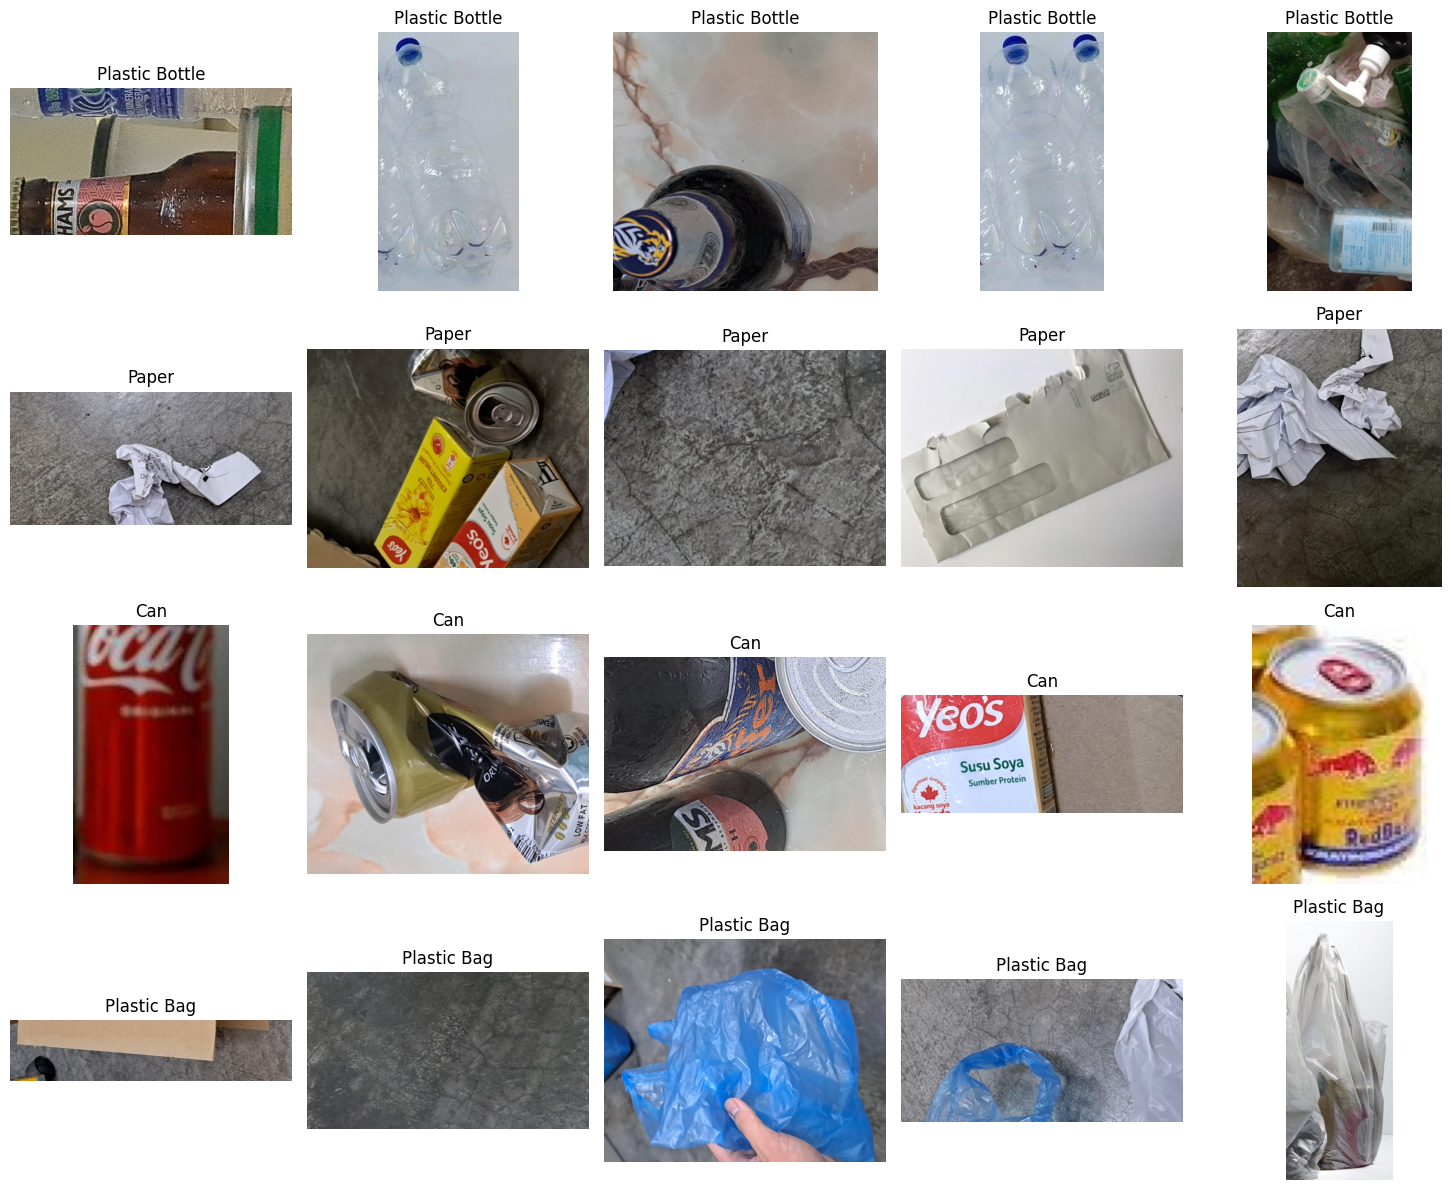

In [21]:
fig, axes = plt.subplots(
    NUM_CLASSES,
    5,
    figsize=(15, NUM_CLASSES * 3)
)

for class_index, class_name in enumerate(CLASS_NAMES):

    samples = manifest[
        (manifest["class_name"] == class_name) &
        (manifest["split"] == "train")
    ]

    samples = samples.sample(
        n=min(5, len(samples)),
        random_state=SEED
    )

    for j in range(5):

        ax = axes[class_index, j]
        ax.axis("off")

        if j < len(samples):

            crop_path = (
                PROCESSED_DIR /
                samples.iloc[j]["crop_path"]
            )

            with Image.open(crop_path) as image:
                ax.imshow(image)

            ax.set_title(class_name)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "sample_grid.png",
    dpi=160
)

plt.show()

Cell 7 — Create class distribution report

class_name,Can,Paper,Plastic Bag,Plastic Bottle
split,,,,
test,65,69,133,91
train,806,468,746,868
val,212,193,281,251


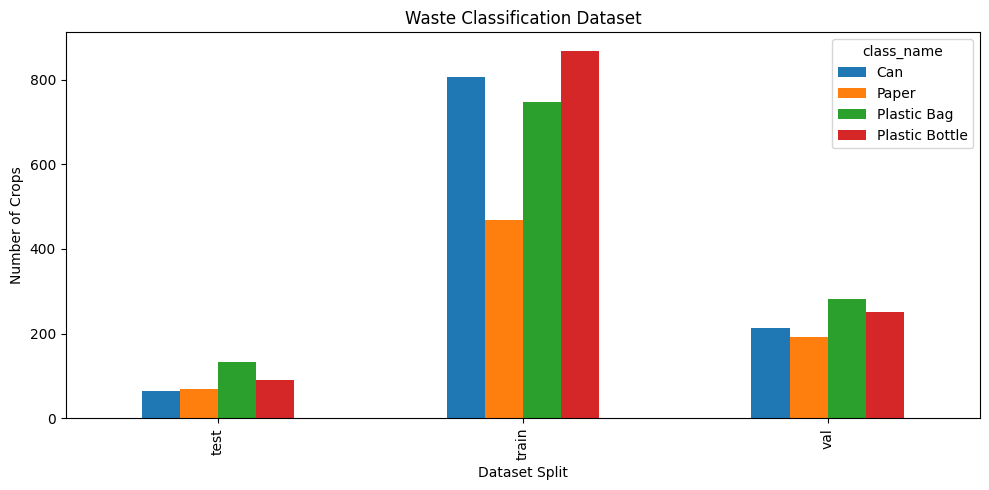

In [22]:
distribution = (
    manifest.groupby(["split", "class_name"])
    .size()
    .unstack(fill_value=0)
)

display(distribution)

distribution.to_csv(
    REPORTS_DIR / "class_distribution.csv"
)

ax = distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Waste Classification Dataset")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Crops")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "class_distribution.png",
    dpi=160
)

plt.show()

Cell 8 — Dataset fingerprint

In [23]:
def file_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


dataset_fingerprint = hashlib.sha256(
    manifest.sort_values("crop_path")[
        ["crop_path", "class_id", "split", "source_sha256"]
    ].to_csv(index=False).encode("utf-8")
).hexdigest()

dataset_metadata = {

    "dataset_name": "Waste Classification Dataset",

    "task": "Image Classification",

    "architecture": "MobileNetV3-Small",

    "classes": CLASS_MAP,

    "seed": SEED,

    "original_split_preserved": True,

    "source_images": int(manifest["source_image"].nunique()),

    "classification_crops": int(len(manifest)),

    "dataset_fingerprint": dataset_fingerprint,

    "source_url": "UNKNOWN",

    "license": "UNKNOWN"

}

with open(
    CONFIG_DIR / "dataset_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_metadata,
        f,
        indent=4
    )

print(json.dumps(dataset_metadata, indent=4))

{
    "dataset_name": "Waste Classification Dataset",
    "task": "Image Classification",
    "architecture": "MobileNetV3-Small",
    "classes": {
        "0": "Plastic Bottle",
        "1": "Paper",
        "2": "Can",
        "3": "Plastic Bag"
    },
    "seed": 42,
    "original_split_preserved": true,
    "source_images": 2074,
    "classification_crops": 4183,
    "dataset_fingerprint": "27acb5a42e5289fb6b0b052a3e567f1f33d1deeb1d9b530a45fcd3bc6916ff98",
    "source_url": "UNKNOWN",
    "license": "UNKNOWN"
}


Cell 9 — Configure MLflow

In [25]:
import mlflow
from pathlib import Path

# Project-specific MLflow database
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"

# SQLite tracking URI (Windows-compatible)
MLFLOW_TRACKING_URI = (
    "sqlite:///" + MLFLOW_DB.resolve().as_posix()
)

# Set tracking backend
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

# Create/select experiment
experiment = mlflow.set_experiment(
    "ModelForge-AI"
)

print("MLflow configured successfully!")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Database:", MLFLOW_DB)

2026/11/17 12:30:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 12:30:02 INFO mlflow.store.db.utils: Updating database tables
2026/11/17 12:30:04 INFO mlflow.tracking.fluent: Experiment with name 'ModelForge-AI' does not exist. Creating a new experiment.


MLflow configured successfully!
Tracking URI: sqlite:///E:/ModelForge-AI/mlflow.db
Experiment name: ModelForge-AI
Experiment ID: 1
Database: E:\ModelForge-AI\mlflow.db


Cell 10 — Log dataset preparation in MLflow

In [ ]:
with mlflow.start_run(
    run_name="dataset-preparation"
) as run:

    mlflow.log_params({

        "seed": SEED,

        "number_of_classes": NUM_CLASSES,

        "architecture": "MobileNetV3-Small",

        "split_strategy": "original_split_preserved",

        "bbox_padding": BBOX_PADDING,

        "image_size": IMAGE_SIZE

    })

    mlflow.log_metrics({

        "total_classification_crops": len(manifest),

        "unique_source_images": manifest["source_image"].nunique(),

        "train_crops": len(manifest[manifest["split"] == "train"]),

        "validation_crops": len(manifest[manifest["split"] == "val"]),

        "test_crops": len(manifest[manifest["split"] == "test"])

    })

    mlflow.set_tags({

        "project": "ModelForge AI",

        "stage": "dataset_preparation",

        "dataset_fingerprint": dataset_fingerprint

    })

    mlflow.log_artifact(
        str(PROCESSED_DIR / "dataset_manifest.csv")
    )

    mlflow.log_artifact(
        str(CONFIG_DIR / "class_map.json")
    )

    mlflow.log_artifact(
        str(CONFIG_DIR / "dataset_metadata.json")
    )

    mlflow.log_artifact(
        str(REPORTS_DIR / "sample_grid.png")
    )

    DATASET_RUN_ID = run.info.run_id

print("Dataset MLflow run:", DATASET_RUN_ID)

Cell 11 — Load classification dataset

In [27]:
# ImageNet normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


# Load datasets
train_dataset = datasets.ImageFolder(
    PROCESSED_DIR / "images" / "train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    PROCESSED_DIR / "images" / "val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    PROCESSED_DIR / "images" / "test",
    transform=eval_transform
)


# Verify that all splits contain identical class folders
assert train_dataset.classes == val_dataset.classes
assert train_dataset.classes == test_dataset.classes

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx


# Convert folder names back to their original class names
folder_to_original = {
    "".join(
        c if c.isalnum() else "_"
        for c in class_name
    ).strip("_"): class_name
    for class_name in CLASS_MAP.values()
}

# This order matches the actual model output indices.
MODEL_CLASS_NAMES = [
    folder_to_original[folder]
    for folder in train_dataset.classes
]

MODEL_CLASS_TO_IDX = train_dataset.class_to_idx

NUM_CLASSES = len(MODEL_CLASS_NAMES)

assert len(MODEL_CLASS_NAMES) == len(CLASS_MAP)


# Save the exact mapping used by the model
MODEL_CLASS_MAPPING = {
    "class_to_idx": MODEL_CLASS_TO_IDX,
    "idx_to_class": {
        str(index): name
        for index, name in enumerate(MODEL_CLASS_NAMES)
    }
}

with open(
    CONFIG_DIR / "model_class_mapping.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        MODEL_CLASS_MAPPING,
        f,
        indent=4
    )


# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)


print("Dataset loaded successfully!")
print("\nModel class mapping:")

for index, name in enumerate(MODEL_CLASS_NAMES):
    print(f"{index}: {name}")

print("\nTraining crops:", len(train_dataset))
print("Validation crops:", len(val_dataset))
print("Test crops:", len(test_dataset))
print("Number of classes:", NUM_CLASSES)

Dataset loaded successfully!

Model class mapping:
0: Can
1: Paper
2: Plastic Bag
3: Plastic Bottle

Training crops: 2888
Validation crops: 937
Test crops: 358
Number of classes: 4


Cell 12 — Create MobileNetV3-Small model

In [28]:
def create_mobilenet(num_classes):

    weights = models.MobileNet_V3_Small_Weights.DEFAULT

    model = models.mobilenet_v3_small(
        weights=weights
    )

    input_features = model.classifier[-1].in_features

    model.classifier[-1] = nn.Linear(
        input_features,
        num_classes
    )

    return model


def freeze_backbone(model):

    for parameter in model.features.parameters():
        parameter.requires_grad = False

    for parameter in model.classifier.parameters():
        parameter.requires_grad = True


def unfreeze_final_block(model):

    for parameter in model.features.parameters():
        parameter.requires_grad = False

    # Unfreeze the final feature block.
    for parameter in model.features[-1].parameters():
        parameter.requires_grad = True

    for parameter in model.classifier.parameters():
        parameter.requires_grad = True


model = create_mobilenet(NUM_CLASSES)

freeze_backbone(model)

model = model.to(DEVICE)

print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\faiza/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:03<00:00, 3.22MB/s]


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), 

Cell 13 — Training and evaluation functions

In [29]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1


@torch.no_grad()
def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0

    all_predictions = []
    all_labels = []

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "predictions": all_predictions,
        "labels": all_labels
    }

Cell 14 — Train Champion v1 with MLflow

In [31]:
CHAMPION_EPOCHS = 5
CHAMPION_LR = 0.001

criterion = nn.CrossEntropyLoss()

model = create_mobilenet(NUM_CLASSES)

freeze_backbone(model)

model = model.to(DEVICE)

optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=CHAMPION_LR
)

best_val_accuracy = -1
best_val_macro_f1 = -1
history = []

with mlflow.start_run(
    run_name="champion-v1"
) as run:

    mlflow.log_params({

        "model": "MobileNetV3-Small",
        "model_version": "champion-v1",
        "epochs": CHAMPION_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": CHAMPION_LR,
        "optimizer": "Adam",
        "frozen_backbone": True,
        "seed": SEED,
        "image_size": IMAGE_SIZE,
        "num_classes": NUM_CLASSES,
        "dataset_fingerprint": dataset_fingerprint

    })

    mlflow.set_tags({

        "project": "ModelForge-AI",
        "model_role": "champion",
        "model_version": "v1",
        "stage": "training"

    })

    for epoch in range(CHAMPION_EPOCHS):

        train_loss, train_acc, train_f1 = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion
        )

        validation = evaluate_model(
            model,
            val_loader,
            criterion
        )

        row = {

            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "val_macro_f1": validation["macro_f1"]

        }

        history.append(row)

        mlflow.log_metrics({

            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "val_macro_f1": validation["macro_f1"]

        }, step=epoch + 1)

        print(f"\nEpoch {epoch + 1}/{CHAMPION_EPOCHS}")
        print(row)

        if validation["accuracy"] > best_val_accuracy:

            best_val_accuracy = validation["accuracy"]
            best_val_macro_f1 = validation["macro_f1"]

            checkpoint = {

                "model_state_dict": copy.deepcopy(
                    model.state_dict()
                ),

                "architecture": "mobilenet_v3_small",

                "num_classes": NUM_CLASSES,

                # Correct mapping from Cell 11
                "class_names": MODEL_CLASS_NAMES,

                "class_to_idx": MODEL_CLASS_TO_IDX,

                "image_size": IMAGE_SIZE,

                "imagenet_mean": IMAGENET_MEAN,

                "imagenet_std": IMAGENET_STD,

                "model_version": "champion-v1",

                "validation_accuracy": best_val_accuracy,

                "validation_macro_f1": best_val_macro_f1,

                "dataset_fingerprint": dataset_fingerprint,

                "training_run_id": run.info.run_id

            }

            torch.save(
                checkpoint,
                CHAMPION_DIR / "champion_v1.pth"
            )

            print("Best Champion checkpoint saved.")

    # Save training history
    history_df = pd.DataFrame(history)

    history_path = REPORTS_DIR / "champion_v1_history.csv"

    history_df.to_csv(
        history_path,
        index=False
    )

    # Log final best validation metrics
    mlflow.log_metrics({

        "best_val_accuracy": best_val_accuracy,

        "best_val_macro_f1": best_val_macro_f1

    })

    # Log artifacts
    mlflow.log_artifact(
        str(CHAMPION_DIR / "champion_v1.pth")
    )

    mlflow.log_artifact(
        str(history_path)
    )

    mlflow.log_artifact(
        str(CONFIG_DIR / "model_class_mapping.json")
    )

    CHAMPION_RUN_ID = run.info.run_id

    mlflow.set_tags({

        "status": "trained",

        "checkpoint": "champion_v1.pth"

    })


print("\n" + "=" * 55)
print("CHAMPION V1 TRAINING COMPLETED")
print("=" * 55)

print("Best validation accuracy:", round(best_val_accuracy, 4))
print("Best validation macro F1:", round(best_val_macro_f1, 4))
print("MLflow Run ID:", CHAMPION_RUN_ID)
print("Checkpoint:", CHAMPION_DIR / "champion_v1.pth")

  0%|          | 0/181 [00:00<?, ?it/s]


Epoch 1/5
{'epoch': 1, 'train_loss': 0.8107586293339399, 'train_accuracy': 0.6651662049861495, 'train_macro_f1': 0.6645752989640847, 'val_loss': 0.9214515096031869, 'val_accuracy': 0.6744930629669157, 'val_macro_f1': 0.6767593620278203}
Best Champion checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Epoch 2/5
{'epoch': 2, 'train_loss': 0.6311541501835113, 'train_accuracy': 0.7583102493074793, 'train_macro_f1': 0.7558354741687061, 'val_loss': 0.8308777141214817, 'val_accuracy': 0.6979722518676628, 'val_macro_f1': 0.6972977736407096}
Best Champion checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Epoch 3/5
{'epoch': 3, 'train_loss': 0.5892015359573417, 'train_accuracy': 0.7714681440443213, 'train_macro_f1': 0.7709815208708686, 'val_loss': 0.6881689048245978, 'val_accuracy': 0.7203842049092849, 'val_macro_f1': 0.7183699017897947}
Best Champion checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Epoch 4/5
{'epoch': 4, 'train_loss': 0.5030108648984386, 'train_accuracy': 0.8012465373961218, 'train_macro_f1': 0.8001813243061144, 'val_loss': 0.6845261150197769, 'val_accuracy': 0.7331910352187834, 'val_macro_f1': 0.7270093485382457}
Best Champion checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Epoch 5/5
{'epoch': 5, 'train_loss': 0.5046609408554938, 'train_accuracy': 0.792590027700831, 'train_macro_f1': 0.7917637703658538, 'val_loss': 0.730048264580577, 'val_accuracy': 0.7107790821771611, 'val_macro_f1': 0.7098567410755074}

CHAMPION V1 TRAINING COMPLETED
Best validation accuracy: 0.7332
Best validation macro F1: 0.727
MLflow Run ID: 192ccd2750ee4e64bcb28212f582ceac
Checkpoint: E:\ModelForge-AI\models\champion\champion_v1.pth


Cell 15 — Load Champion v1 checkpoint

In [32]:
CHAMPION_PATH = CHAMPION_DIR / "champion_v1.pth"

assert CHAMPION_PATH.exists(), "Champion v1 checkpoint not found!"

champion_checkpoint = torch.load(
    CHAMPION_PATH,
    map_location=DEVICE,
    weights_only=False
)

champion_model = create_mobilenet(NUM_CLASSES)

champion_model.load_state_dict(
    champion_checkpoint["model_state_dict"]
)

champion_model = champion_model.to(DEVICE)
champion_model.eval()

print("Champion v1 loaded successfully.")
print("Validation Accuracy:", champion_checkpoint["validation_accuracy"])
print("Validation Macro F1:", champion_checkpoint["validation_macro_f1"])
print("Training Run:", champion_checkpoint["training_run_id"])

Champion v1 loaded successfully.
Validation Accuracy: 0.7331910352187834
Validation Macro F1: 0.7270093485382457
Training Run: 192ccd2750ee4e64bcb28212f582ceac


Cell 16 — Create Challenger v2 from Champion v1

In [33]:
CHALLENGER_EPOCHS = 3
CHALLENGER_LR = 0.0001

challenger_model = create_mobilenet(NUM_CLASSES)

# Initialize from Champion v1
challenger_model.load_state_dict(
    champion_checkpoint["model_state_dict"]
)

# Unfreeze final feature block and classifier
unfreeze_final_block(challenger_model)

challenger_model = challenger_model.to(DEVICE)

challenger_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        challenger_model.parameters()
    ),
    lr=CHALLENGER_LR,
    weight_decay=0.01
)

print("Challenger v2 initialized from Champion v1.")

print(
    "Trainable parameters:",
    sum(p.numel() for p in challenger_model.parameters() if p.requires_grad)
)

print(
    "Total parameters:",
    sum(p.numel() for p in challenger_model.parameters())
)

Challenger v2 initialized from Champion v1.
Trainable parameters: 651396
Total parameters: 1521956


Cell 17 — Train Challenger v2 with MLflow

In [34]:
best_challenger_accuracy = -1
best_challenger_f1 = -1

challenger_history = []

with mlflow.start_run(
    run_name="challenger-v2"
) as run:

    mlflow.log_params({

        "model": "MobileNetV3-Small",
        "model_version": "challenger-v2",
        "initialized_from": "champion-v1",
        "epochs": CHALLENGER_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": CHALLENGER_LR,
        "optimizer": "AdamW",
        "fine_tuned_layer": "features[-1]",
        "seed": SEED,
        "dataset_fingerprint": dataset_fingerprint

    })

    mlflow.set_tags({

        "project": "ModelForge-AI",
        "model_role": "challenger",
        "model_version": "v2",
        "parent_run_id": CHAMPION_RUN_ID

    })

    for epoch in range(CHALLENGER_EPOCHS):

        train_loss, train_acc, train_f1 = train_one_epoch(
            challenger_model,
            train_loader,
            challenger_optimizer,
            criterion
        )

        validation = evaluate_model(
            challenger_model,
            val_loader,
            criterion
        )

        row = {

            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "val_macro_f1": validation["macro_f1"]

        }

        challenger_history.append(row)

        mlflow.log_metrics({

            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "val_macro_f1": validation["macro_f1"]

        }, step=epoch + 1)

        print(f"\nChallenger Epoch {epoch + 1}/{CHALLENGER_EPOCHS}")
        print(row)

        if validation["accuracy"] > best_challenger_accuracy:

            best_challenger_accuracy = validation["accuracy"]
            best_challenger_f1 = validation["macro_f1"]

            challenger_checkpoint = {

                "model_state_dict": copy.deepcopy(
                    challenger_model.state_dict()
                ),

                "architecture": "mobilenet_v3_small",
                "num_classes": NUM_CLASSES,
                "class_names": MODEL_CLASS_NAMES,
                "class_to_idx": MODEL_CLASS_TO_IDX,
                "image_size": IMAGE_SIZE,
                "imagenet_mean": IMAGENET_MEAN,
                "imagenet_std": IMAGENET_STD,
                "model_version": "challenger-v2",
                "validation_accuracy": best_challenger_accuracy,
                "validation_macro_f1": best_challenger_f1,
                "dataset_fingerprint": dataset_fingerprint,
                "parent_champion_run_id": CHAMPION_RUN_ID,
                "training_run_id": run.info.run_id

            }

            torch.save(
                challenger_checkpoint,
                CANDIDATES_DIR / "challenger_v2.pth"
            )

            print("Best Challenger checkpoint saved.")

    challenger_history_df = pd.DataFrame(challenger_history)

    challenger_history_path = (
        REPORTS_DIR / "challenger_v2_history.csv"
    )

    challenger_history_df.to_csv(
        challenger_history_path,
        index=False
    )

    mlflow.log_metrics({

        "best_val_accuracy": best_challenger_accuracy,
        "best_val_macro_f1": best_challenger_f1

    })

    mlflow.log_artifact(
        str(CANDIDATES_DIR / "challenger_v2.pth")
    )

    mlflow.log_artifact(
        str(challenger_history_path)
    )

    CHALLENGER_RUN_ID = run.info.run_id

    mlflow.set_tags({
        "status": "trained"
    })


print("\nCHALLENGER V2 TRAINING COMPLETED")
print("Best Validation Accuracy:", best_challenger_accuracy)
print("Best Validation Macro F1:", best_challenger_f1)
print("MLflow Run ID:", CHALLENGER_RUN_ID)

  0%|          | 0/181 [00:00<?, ?it/s]


Challenger Epoch 1/3
{'epoch': 1, 'train_loss': 0.4234153771994847, 'train_accuracy': 0.8414127423822715, 'train_macro_f1': 0.8421303063566247, 'val_loss': 0.704300572294563, 'val_accuracy': 0.7257203842049093, 'val_macro_f1': 0.7247468583910331}
Best Challenger checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Challenger Epoch 2/3
{'epoch': 2, 'train_loss': 0.4060262144024683, 'train_accuracy': 0.8462603878116344, 'train_macro_f1': 0.8454934742416788, 'val_loss': 0.6805610534920891, 'val_accuracy': 0.7289220917822838, 'val_macro_f1': 0.7262586350420321}
Best Challenger checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]


Challenger Epoch 3/3
{'epoch': 3, 'train_loss': 0.39357925018610385, 'train_accuracy': 0.8483379501385041, 'train_macro_f1': 0.8485743332661231, 'val_loss': 0.6816404761474186, 'val_accuracy': 0.7246531483457844, 'val_macro_f1': 0.7203596107547283}

CHALLENGER V2 TRAINING COMPLETED
Best Validation Accuracy: 0.7289220917822838
Best Validation Macro F1: 0.7262586350420321
MLflow Run ID: 678ab9a5a14841c7b63dc45b8d5db3e5


Cell 18 — Compare Champion and Challenger

,Model,Validation Accuracy,Validation Macro F1
0,Champion v1,0.733191,0.727009
1,Challenger v2,0.728922,0.726259


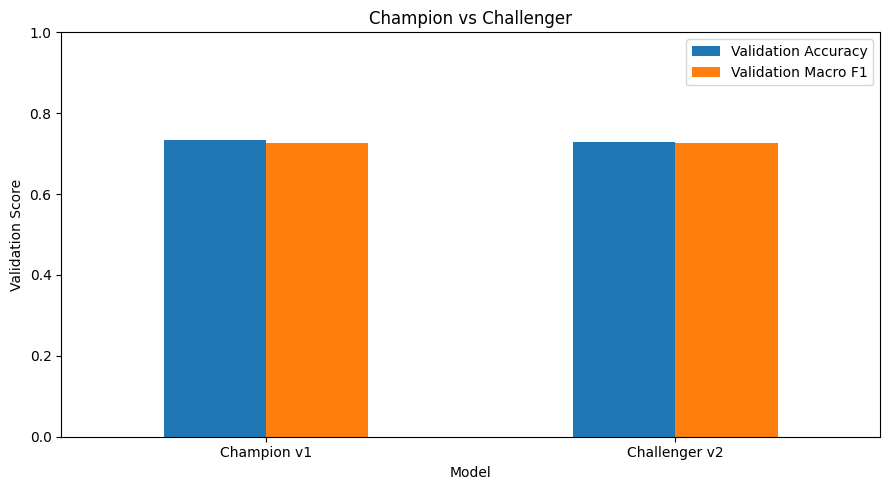

In [35]:
comparison = pd.DataFrame([

    {
        "Model": "Champion v1",
        "Validation Accuracy": champion_checkpoint["validation_accuracy"],
        "Validation Macro F1": champion_checkpoint["validation_macro_f1"]
    },

    {
        "Model": "Challenger v2",
        "Validation Accuracy": best_challenger_accuracy,
        "Validation Macro F1": best_challenger_f1
    }

])

display(comparison)

comparison.to_csv(
    REPORTS_DIR / "champion_challenger_comparison.csv",
    index=False
)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)

plt.title("Champion vs Challenger")
plt.ylabel("Validation Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "champion_challenger_comparison.png",
    dpi=160
)

plt.show()

Cell 19 — Promotion decision

In [36]:
MIN_ACCURACY_IMPROVEMENT = 0.005
MAX_MACRO_F1_DECREASE = 0.01

accuracy_improvement = (
    best_challenger_accuracy -
    champion_checkpoint["validation_accuracy"]
)

macro_f1_change = (
    best_challenger_f1 -
    champion_checkpoint["validation_macro_f1"]
)

same_dataset = (
    challenger_checkpoint["dataset_fingerprint"]
    == champion_checkpoint["dataset_fingerprint"]
)

same_classes = (
    challenger_checkpoint["class_to_idx"]
    == champion_checkpoint["class_to_idx"]
)

# Load candidate and perform inference smoke test
candidate_test_model = create_mobilenet(NUM_CLASSES)

candidate_test_model.load_state_dict(
    challenger_checkpoint["model_state_dict"]
)

candidate_test_model.eval()

sample_images, _ = next(iter(val_loader))

with torch.no_grad():

    smoke_output = candidate_test_model(
        sample_images[:1].to(DEVICE)
    )

smoke_test_passed = (
    smoke_output.shape == (1, NUM_CLASSES)
    and torch.isfinite(smoke_output).all().item()
)

promotion_checks = {

    "accuracy_improvement_passed":
        accuracy_improvement >= MIN_ACCURACY_IMPROVEMENT,

    "macro_f1_passed":
        macro_f1_change >= -MAX_MACRO_F1_DECREASE,

    "same_dataset":
        same_dataset,

    "same_class_mapping":
        same_classes,

    "smoke_test_passed":
        smoke_test_passed,

    "finite_metrics":
        np.isfinite(best_challenger_accuracy)
        and np.isfinite(best_challenger_f1)

}

PROMOTE_CHALLENGER = all(promotion_checks.values())

print("Promotion checks:")

for check, result in promotion_checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

print("\nAccuracy improvement:", round(accuracy_improvement, 5))
print("Macro-F1 change:", round(macro_f1_change, 5))

print(
    "\nFINAL DECISION:",
    "PROMOTE CHALLENGER V2"
    if PROMOTE_CHALLENGER
    else "REJECT CHALLENGER V2"
)

Promotion checks:
accuracy_improvement_passed: FAIL
macro_f1_passed: PASS
same_dataset: PASS
same_class_mapping: PASS
smoke_test_passed: PASS
finite_metrics: PASS

Accuracy improvement: -0.00427
Macro-F1 change: -0.00075

FINAL DECISION: REJECT CHALLENGER V2


Cell 20 — Promote or reject with rollback protection

In [42]:

print("AVAILABLE MODEL METRICS")
print("=" * 50)

# Take a snapshot to avoid dictionary-changed-size errors
available_variables = list(globals().items())

for name, value in available_variables:

    if any(word in name.lower() for word in [
        "metric", "accuracy", "f1", "champion", "challenger",
        "history", "checkpoint"
    ]):

        if isinstance(value, dict):
            print(f"\n{name}:")
            print("Keys:", list(value.keys()))

        elif isinstance(value, (list, tuple)):
            print(
                f"\n{name}: {type(value).__name__}, "
                f"length={len(value)}"
            )

        elif isinstance(value, (int, float)):
            print(f"{name}: {value}")

print("\nSAVED CHECKPOINTS")
print("=" * 50)

for path in [
    CHAMPION_DIR / "champion_v1.pth",
    CANDIDATES_DIR / "challenger_v2.pth"
]:
    print(path.name, "EXISTS:", path.exists())


AVAILABLE MODEL METRICS
CHAMPION_EPOCHS: 5
CHAMPION_LR: 0.001
best_val_accuracy: 0.7331910352187834

history: list, length=5
best_val_macro_f1: 0.7270093485382457
train_f1: 0.8485743332661231

checkpoint:
Keys: ['model_state_dict', 'architecture', 'num_classes', 'class_names', 'class_to_idx', 'image_size', 'imagenet_mean', 'imagenet_std', 'model_version', 'validation_accuracy', 'validation_macro_f1', 'dataset_fingerprint', 'training_run_id']

champion_checkpoint:
Keys: ['model_state_dict', 'architecture', 'num_classes', 'class_names', 'class_to_idx', 'image_size', 'imagenet_mean', 'imagenet_std', 'model_version', 'validation_accuracy', 'validation_macro_f1', 'dataset_fingerprint', 'training_run_id']
CHALLENGER_EPOCHS: 3
CHALLENGER_LR: 0.0001
best_challenger_accuracy: 0.7289220917822838
best_challenger_f1: 0.7262586350420321

challenger_history: list, length=3

challenger_checkpoint:
Keys: ['model_state_dict', 'architecture', 'num_classes', 'class_names', 'class_to_idx', 'image_size', '

In [43]:

import json
import shutil
import numpy as np
import torch
import mlflow

from pathlib import Path
from datetime import datetime, timezone

# ============================================================
# CELL 40: CHAMPION-CHALLENGER PROMOTION DECISION
# ============================================================

ACTIVE_CHAMPION_PATH = CHAMPION_DIR / "champion.pth"
CHAMPION_V1_PATH = CHAMPION_DIR / "champion_v1.pth"
CANDIDATE_PATH = CANDIDATES_DIR / "challenger_v2.pth"

BACKUP_DIR = CHAMPION_DIR / "backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

MIN_ACCURACY_IMPROVEMENT = 0.005
MAX_MACRO_F1_DECREASE = 0.01

print("=" * 65)
print("MODEL PROMOTION EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY CHECKPOINT FILES
# ------------------------------------------------------------

if not CHAMPION_V1_PATH.exists():
    raise FileNotFoundError(f"Champion v1 missing: {CHAMPION_V1_PATH}")

if not CANDIDATE_PATH.exists():
    raise FileNotFoundError(f"Challenger v2 missing: {CANDIDATE_PATH}")

# Load the actual saved checkpoints
champion_checkpoint = torch.load(
    CHAMPION_V1_PATH,
    map_location=DEVICE,
    weights_only=False
)

challenger_checkpoint = torch.load(
    CANDIDATE_PATH,
    map_location=DEVICE,
    weights_only=False
)

# ------------------------------------------------------------
# 2. EXTRACT ACTUAL VALIDATION METRICS
# ------------------------------------------------------------

champion_accuracy = float(
    champion_checkpoint["validation_accuracy"]
)

champion_f1 = float(
    champion_checkpoint["validation_macro_f1"]
)

challenger_accuracy = float(
    challenger_checkpoint["validation_accuracy"]
)

challenger_f1 = float(
    challenger_checkpoint["validation_macro_f1"]
)

accuracy_gain = challenger_accuracy - champion_accuracy
macro_f1_change = challenger_f1 - champion_f1

metrics_finite = all(
    np.isfinite(value)
    for value in [
        champion_accuracy,
        champion_f1,
        challenger_accuracy,
        challenger_f1
    ]
)

# ------------------------------------------------------------
# 3. CHECK PROMOTION CONDITIONS
# ------------------------------------------------------------

accuracy_pass = (
    accuracy_gain >= MIN_ACCURACY_IMPROVEMENT
)

macro_f1_pass = (
    macro_f1_change >= -MAX_MACRO_F1_DECREASE
)

same_dataset = (
    champion_checkpoint["dataset_fingerprint"]
    == challenger_checkpoint["dataset_fingerprint"]
)

same_class_mapping = (
    champion_checkpoint["class_names"]
    == challenger_checkpoint["class_names"]
    and champion_checkpoint["class_to_idx"]
    == challenger_checkpoint["class_to_idx"]
)

# ------------------------------------------------------------
# 4. VERIFY CANDIDATE MODEL LOADING AND INFERENCE
# ------------------------------------------------------------

candidate_loads = False
smoke_test_pass = False

try:

    candidate_model = create_mobilenet(NUM_CLASSES)

    candidate_model.load_state_dict(
        challenger_checkpoint["model_state_dict"]
    )

    candidate_model = candidate_model.to(DEVICE)
    candidate_model.eval()

    candidate_loads = True

    sample_images, _ = next(iter(val_loader))
    sample_images = sample_images[:2].to(DEVICE)

    with torch.no_grad():
        outputs = candidate_model(sample_images)

    smoke_test_pass = bool(
        outputs.ndim == 2
        and outputs.shape[1] == NUM_CLASSES
        and torch.isfinite(outputs).all().item()
    )

except Exception as error:

    print("Candidate verification error:", str(error))

# ------------------------------------------------------------
# 5. FINAL PROMOTION GATES
# ------------------------------------------------------------

promotion_checks = {
    "accuracy_improvement": bool(accuracy_pass),
    "macro_f1_requirement": bool(macro_f1_pass),
    "same_dataset": bool(same_dataset),
    "same_class_mapping": bool(same_class_mapping),
    "finite_metrics": bool(metrics_finite),
    "candidate_loads": bool(candidate_loads),
    "smoke_test_pass": bool(smoke_test_pass)
}

all_checks_pass = all(promotion_checks.values())

# ------------------------------------------------------------
# 6. INITIALIZE PROMOTION REPORT
# ------------------------------------------------------------

promotion_result = {
    "timestamp": datetime.now(timezone.utc).isoformat(),

    "champion_version": champion_checkpoint["model_version"],
    "challenger_version": challenger_checkpoint["model_version"],

    "champion_accuracy": champion_accuracy,
    "challenger_accuracy": challenger_accuracy,
    "accuracy_gain": accuracy_gain,

    "champion_macro_f1": champion_f1,
    "challenger_macro_f1": challenger_f1,
    "macro_f1_change": macro_f1_change,

    "minimum_accuracy_improvement": MIN_ACCURACY_IMPROVEMENT,
    "maximum_macro_f1_decrease": MAX_MACRO_F1_DECREASE,

    "checks": promotion_checks,

    "promoted": False,
    "decision": "REJECTED",
    "reason": "One or more promotion conditions failed",

    "backup_created": False
}

# ------------------------------------------------------------
# 7. PROMOTE OR REJECT
# ------------------------------------------------------------

if all_checks_pass:

    # Back up the currently active Champion, if one exists
    if ACTIVE_CHAMPION_PATH.exists():

        backup_path = BACKUP_DIR / (
            "champion_backup_"
            + datetime.now().strftime("%Y%m%d_%H%M%S")
            + ".pth"
        )

        shutil.copy2(
            ACTIVE_CHAMPION_PATH,
            backup_path
        )

        promotion_result["backup_created"] = True
        promotion_result["backup_path"] = str(backup_path)

    # Promote Challenger v2
    shutil.copy2(
        CANDIDATE_PATH,
        ACTIVE_CHAMPION_PATH
    )

    promotion_result.update({
        "promoted": True,
        "decision": "PROMOTED",
        "reason": "All promotion conditions passed",
        "active_model": str(ACTIVE_CHAMPION_PATH)
    })

    print("\nCHALLENGER V2 PROMOTED!")

else:

    # Never overwrite an existing approved Champion
    if not ACTIVE_CHAMPION_PATH.exists():

        shutil.copy2(
            CHAMPION_V1_PATH,
            ACTIVE_CHAMPION_PATH
        )

    promotion_result.update({
        "promoted": False,
        "decision": "REJECTED",
        "reason": "Challenger failed one or more promotion gates",
        "active_model": str(ACTIVE_CHAMPION_PATH)
    })

    print("\nCHALLENGER V2 REJECTED.")
    print("Champion v1 remains the approved model.")

# ------------------------------------------------------------
# 8. SAVE PROMOTION DECISION JSON
# ------------------------------------------------------------

decision_path = REPORTS_DIR / "promotion_decision.json"

with open(
    decision_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        promotion_result,
        file,
        indent=4,
        allow_nan=False
    )

# ------------------------------------------------------------
# 9. LOG PROMOTION DECISION TO MLFLOW
# ------------------------------------------------------------

try:

    with mlflow.start_run(
        run_name="champion-challenger-promotion"
    ) as promotion_run:

        mlflow.log_params({
            "champion_version": str(champion_checkpoint["model_version"]),
            "challenger_version": str(challenger_checkpoint["model_version"]),
            "minimum_accuracy_improvement": MIN_ACCURACY_IMPROVEMENT,
            "maximum_macro_f1_decrease": MAX_MACRO_F1_DECREASE
        })

        mlflow.log_metrics({
            "champion_val_accuracy": champion_accuracy,
            "challenger_val_accuracy": challenger_accuracy,
            "accuracy_gain": accuracy_gain,
            "champion_val_macro_f1": champion_f1,
            "challenger_val_macro_f1": challenger_f1,
            "macro_f1_change": macro_f1_change
        })

        mlflow.set_tags({
            "promotion_decision": promotion_result["decision"],
            "promotion_reason": promotion_result["reason"],
            "model_stage": "promotion_evaluation"
        })

        mlflow.log_artifact(str(decision_path))

        promotion_result["mlflow_run_id"] = promotion_run.info.run_id

except Exception as error:

    print("\nMLflow decision logging warning:", str(error))

# ------------------------------------------------------------
# 10. DISPLAY FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL PROMOTION REPORT")
print("=" * 65)

print(f"\nChampion v1 Accuracy : {champion_accuracy:.4f}")
print(f"Challenger v2 Accuracy: {challenger_accuracy:.4f}")
print(f"Accuracy Gain         : {accuracy_gain:+.4f}")

print(f"\nChampion v1 Macro-F1 : {champion_f1:.4f}")
print(f"Challenger v2 Macro-F1: {challenger_f1:.4f}")
print(f"Macro-F1 Change       : {macro_f1_change:+.4f}")

print("\nPROMOTION CHECKS")
print("-" * 65)

for check, passed in promotion_checks.items():
    print(f"{check:<30} {'PASS' if passed else 'FAIL'}")

print("\nFINAL DECISION:", promotion_result["decision"])
print("Decision report:", decision_path)
print("Active Champion:", ACTIVE_CHAMPION_PATH)
print("=" * 65)


MODEL PROMOTION EVALUATION

CHALLENGER V2 REJECTED.
Champion v1 remains the approved model.

FINAL PROMOTION REPORT

Champion v1 Accuracy : 0.7332
Challenger v2 Accuracy: 0.7289
Accuracy Gain         : -0.0043

Champion v1 Macro-F1 : 0.7270
Challenger v2 Macro-F1: 0.7263
Macro-F1 Change       : -0.0008

PROMOTION CHECKS
-----------------------------------------------------------------
accuracy_improvement           FAIL
macro_f1_requirement           PASS
same_dataset                   PASS
same_class_mapping             PASS
finite_metrics                 PASS
candidate_loads                PASS
smoke_test_pass                PASS

FINAL DECISION: REJECTED
Decision report: E:\ModelForge-AI\reports\promotion_decision.json
Active Champion: E:\ModelForge-AI\models\champion\champion.pth


In [ ]:
Cell 42 — Train Challenger v3

In [50]:

# ============================================================
# CELL 44: CHALLENGER V3 - COMPLETE TRAINING PIPELINE
# ============================================================

import copy
import json
import numpy as np
import torch
import torch.nn as nn
import mlflow

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHALLENGER_V3_EPOCHS = 8
CHALLENGER_V3_LR = 0.00003
CHALLENGER_V3_PATIENCE = 3
CHALLENGER_V3_WEIGHT_DECAY = 0.0001

V3_CHECKPOINT_PATH = CANDIDATES_DIR / "challenger_v3.pth"
V3_HISTORY_PATH = REPORTS_DIR / "challenger_v3_history.json"

CANDIDATES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("CHALLENGER V3 TRAINING")
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD CHAMPION V1
# ------------------------------------------------------------

champion_checkpoint = torch.load(
    CHAMPION_DIR / "champion_v1.pth",
    map_location=DEVICE,
    weights_only=False
)

challenger_v3 = create_mobilenet(NUM_CLASSES)

challenger_v3.load_state_dict(
    champion_checkpoint["model_state_dict"]
)

challenger_v3 = challenger_v3.to(DEVICE)

# ------------------------------------------------------------
# 3. PARTIAL FINE-TUNING
# ------------------------------------------------------------

# Freeze all feature layers
for param in challenger_v3.features.parameters():
    param.requires_grad = False

# Unfreeze final two feature blocks
for param in challenger_v3.features[-2:].parameters():
    param.requires_grad = True

# Unfreeze classification head
for param in challenger_v3.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in challenger_v3.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in challenger_v3.parameters()
)

print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

# ------------------------------------------------------------
# 4. LOSS AND OPTIMIZER
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        challenger_v3.parameters()
    ),
    lr=CHALLENGER_V3_LR,
    weight_decay=CHALLENGER_V3_WEIGHT_DECAY
)

# ------------------------------------------------------------
# 5. INITIALIZE TRAINING VARIABLES
# ------------------------------------------------------------

best_v3_accuracy = -1.0
best_v3_f1 = -1.0
best_v3_loss = float("inf")
best_v3_epoch = 0

best_v3_state = None

epochs_without_improvement = 0
challenger_v3_history = []

# ------------------------------------------------------------
# 6. START MLFLOW RUN
# ------------------------------------------------------------

with mlflow.start_run(
    run_name="challenger-v3-two-block-finetuning"
) as v3_run:

    V3_RUN_ID = v3_run.info.run_id

    mlflow.log_params({
        "model_version": "challenger_v3",
        "architecture": "MobileNetV3-Small",
        "initialization": "champion_v1",
        "unfrozen_feature_blocks": 2,
        "epochs": CHALLENGER_V3_EPOCHS,
        "learning_rate": CHALLENGER_V3_LR,
        "optimizer": "AdamW",
        "weight_decay": CHALLENGER_V3_WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "image_size": IMAGE_SIZE,
        "num_classes": NUM_CLASSES,
        "early_stopping_patience": CHALLENGER_V3_PATIENCE,
        "dataset_fingerprint": champion_checkpoint[
            "dataset_fingerprint"
        ]
    })

    mlflow.set_tags({
        "model_role": "challenger",
        "model_version": "v3",
        "parent_model": "champion_v1",
        "training_strategy": "partial_finetuning"
    })

    # --------------------------------------------------------
    # 7. TRAINING LOOP
    # --------------------------------------------------------

    for epoch in range(CHALLENGER_V3_EPOCHS):

        # Train
        train_loss, train_accuracy, train_f1 = train_one_epoch(
            challenger_v3,
            train_loader,
            optimizer,
            criterion
        )

        # Validate - evaluate_model returns a dictionary
        val_results = evaluate_model(
            challenger_v3,
            val_loader,
            criterion
        )

        val_loss = val_results["loss"]
        val_accuracy = val_results["accuracy"]
        val_f1 = val_results["macro_f1"]

        # Convert metrics to Python floats
        train_loss = float(train_loss)
        train_accuracy = float(train_accuracy)
        train_f1 = float(train_f1)

        val_loss = float(val_loss)
        val_accuracy = float(val_accuracy)
        val_f1 = float(val_f1)

        # Record history
        epoch_record = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "train_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_f1
        }

        challenger_v3_history.append(epoch_record)

        # Log epoch metrics to MLflow
        mlflow.log_metrics({
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "train_macro_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_f1
        }, step=epoch + 1)

        print(
            f"Epoch {epoch + 1}/{CHALLENGER_V3_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Train F1: {train_f1:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        # ----------------------------------------------------
        # 8. VALIDATE METRICS AND SAVE BEST MODEL
        # ----------------------------------------------------

        metrics_are_valid = all(
            np.isfinite(value)
            for value in [
                train_loss,
                train_accuracy,
                train_f1,
                val_loss,
                val_accuracy,
                val_f1
            ]
        )

        if metrics_are_valid and val_accuracy > best_v3_accuracy:

            best_v3_accuracy = val_accuracy
            best_v3_f1 = val_f1
            best_v3_loss = val_loss
            best_v3_epoch = epoch + 1

            best_v3_state = copy.deepcopy(
                challenger_v3.state_dict()
            )

            epochs_without_improvement = 0

            v3_checkpoint = {
                "model_state_dict": best_v3_state,
                "architecture": "MobileNetV3-Small",
                "num_classes": NUM_CLASSES,
                "class_names": MODEL_CLASS_NAMES,
                "class_to_idx": MODEL_CLASS_TO_IDX,
                "image_size": IMAGE_SIZE,
                "imagenet_mean": [0.485, 0.456, 0.406],
                "imagenet_std": [0.229, 0.224, 0.225],
                "model_version": "challenger_v3",
                "validation_accuracy": best_v3_accuracy,
                "validation_macro_f1": best_v3_f1,
                "dataset_fingerprint": champion_checkpoint[
                    "dataset_fingerprint"
                ],
                "parent_champion_run_id": champion_checkpoint[
                    "training_run_id"
                ],
                "training_run_id": V3_RUN_ID
            }

            torch.save(
                v3_checkpoint,
                V3_CHECKPOINT_PATH
            )

            print("Best v3 checkpoint saved.")

        else:
            epochs_without_improvement += 1

        # ----------------------------------------------------
        # 9. EARLY STOPPING
        # ----------------------------------------------------

        if epochs_without_improvement >= CHALLENGER_V3_PATIENCE:
            print("\nEarly stopping triggered.")
            break

    # --------------------------------------------------------
    # 10. RESTORE BEST WEIGHTS
    # --------------------------------------------------------

    if best_v3_state is None:
        raise RuntimeError(
            "No valid v3 checkpoint was produced. "
            "Check training and validation metrics."
        )

    challenger_v3.load_state_dict(best_v3_state)

    mlflow.log_metrics({
        "best_val_accuracy": best_v3_accuracy,
        "best_val_macro_f1": best_v3_f1,
        "best_val_loss": best_v3_loss,
        "best_epoch": best_v3_epoch
    })

    mlflow.log_artifact(str(V3_CHECKPOINT_PATH))

    mlflow.set_tag("training_status", "completed")

# ------------------------------------------------------------
# 11. SAVE TRAINING HISTORY
# ------------------------------------------------------------

with open(
    V3_HISTORY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        challenger_v3_history,
        f,
        indent=4,
        allow_nan=False
    )

# ------------------------------------------------------------
# 12. FINAL RESULTS
# ------------------------------------------------------------

best_challenger_v3_accuracy = best_v3_accuracy
best_challenger_v3_f1 = best_v3_f1

print("\n" + "=" * 65)
print("CHALLENGER V3 TRAINING COMPLETED")
print("=" * 65)

print("Best Epoch:", best_v3_epoch)
print(f"Validation Accuracy: {best_v3_accuracy:.4f}")
print(f"Validation Macro-F1: {best_v3_f1:.4f}")
print("MLflow Run ID:", V3_RUN_ID)
print("Checkpoint:", V3_CHECKPOINT_PATH)
print("History:", V3_HISTORY_PATH)

print("=" * 65)


CHALLENGER V3 TRAINING
Trainable parameters: 945,492
Frozen parameters: 576,464
Trainable percentage: 62.12%


  0%|          | 0/181 [00:00<?, ?it/s]

Epoch 1/8 | Train Loss: 0.4376 | Train Acc: 0.8338 | Train F1: 0.8344 | Val Loss: 0.7067 | Val Acc: 0.7236 | Val F1: 0.7210
Best v3 checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]

Epoch 2/8 | Train Loss: 0.4045 | Train Acc: 0.8511 | Train F1: 0.8513 | Val Loss: 0.6948 | Val Acc: 0.7279 | Val F1: 0.7257
Best v3 checkpoint saved.


  0%|          | 0/181 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/181 [00:00<?, ?it/s]

Epoch 7/8 | Train Loss: 0.3486 | Train Acc: 0.8750 | Train F1: 0.8741 | Val Loss: 0.6752 | Val Acc: 0.7364 | Val F1: 0.7341


  0%|          | 0/181 [00:00<?, ?it/s]

Epoch 8/8 | Train Loss: 0.3414 | Train Acc: 0.8736 | Train F1: 0.8741 | Val Loss: 0.6962 | Val Acc: 0.7417 | Val F1: 0.7422

CHALLENGER V3 TRAINING COMPLETED
Best Epoch: 6
Validation Accuracy: 0.7417
Validation Macro-F1: 0.7408
MLflow Run ID: 430b5dacf59f46489ad52095ce0ca463
Checkpoint: E:\ModelForge-AI\models\candidates\challenger_v3.pth
History: E:\ModelForge-AI\reports\challenger_v3_history.json


In [51]:
# ============================================================
# CELL 45: CHALLENGER V3 PROMOTION GATES
# ============================================================

import torch
import numpy as np
import json
import shutil
from datetime import datetime
import mlflow

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MIN_ACCURACY_IMPROVEMENT = 0.005
MAX_MACRO_F1_DECREASE = 0.01

V1_PATH = CHAMPION_DIR / "champion_v1.pth"
V3_PATH = CANDIDATES_DIR / "challenger_v3.pth"
ACTIVE_CHAMPION_PATH = CHAMPION_DIR / "champion.pth"

DECISION_PATH = REPORTS_DIR / "challenger_v3_promotion.json"

# ------------------------------------------------------------
# 2. LOAD CHECKPOINTS
# ------------------------------------------------------------

v1_checkpoint = torch.load(
    V1_PATH,
    map_location=DEVICE,
    weights_only=False
)

v3_checkpoint = torch.load(
    V3_PATH,
    map_location=DEVICE,
    weights_only=False
)

v1_accuracy = float(v1_checkpoint["validation_accuracy"])
v1_f1 = float(v1_checkpoint["validation_macro_f1"])

v3_accuracy = float(v3_checkpoint["validation_accuracy"])
v3_f1 = float(v3_checkpoint["validation_macro_f1"])

accuracy_gain = v3_accuracy - v1_accuracy
macro_f1_change = v3_f1 - v1_f1

# ------------------------------------------------------------
# 3. CHECK PROMOTION REQUIREMENTS
# ------------------------------------------------------------

checks = {}

checks["accuracy_improvement"] = (
    np.isfinite(accuracy_gain)
    and accuracy_gain >= MIN_ACCURACY_IMPROVEMENT
)

checks["macro_f1_requirement"] = (
    np.isfinite(macro_f1_change)
    and macro_f1_change >= -MAX_MACRO_F1_DECREASE
)

checks["finite_metrics"] = all(
    np.isfinite(x)
    for x in [v1_accuracy, v1_f1, v3_accuracy, v3_f1]
)

checks["same_dataset"] = (
    v1_checkpoint["dataset_fingerprint"]
    == v3_checkpoint["dataset_fingerprint"]
    == champion_checkpoint["dataset_fingerprint"]
)

checks["same_class_names"] = (
    list(v1_checkpoint["class_names"])
    == list(v3_checkpoint["class_names"])
    == list(MODEL_CLASS_NAMES)
)

checks["same_class_mapping"] = (
    v1_checkpoint["class_to_idx"]
    == v3_checkpoint["class_to_idx"]
    == MODEL_CLASS_TO_IDX
)

# ------------------------------------------------------------
# 4. CHECK MODEL LOADING AND SMOKE INFERENCE
# ------------------------------------------------------------

smoke_test_passed = False

try:
    smoke_model = create_mobilenet(NUM_CLASSES)

    smoke_model.load_state_dict(
        v3_checkpoint["model_state_dict"]
    )

    smoke_model = smoke_model.to(DEVICE)
    smoke_model.eval()

    sample_images, _ = next(iter(val_loader))
    sample_images = sample_images[:2].to(DEVICE)

    with torch.no_grad():
        smoke_output = smoke_model(sample_images)

    smoke_test_passed = (
        smoke_output.shape[0] == sample_images.shape[0]
        and smoke_output.shape[1] == NUM_CLASSES
        and torch.isfinite(smoke_output).all().item()
    )

except Exception as error:
    print("Smoke test error:", error)
    smoke_test_passed = False

checks["checkpoint_load_and_smoke_test"] = smoke_test_passed

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 65)
print("CHALLENGER V3 PROMOTION EVALUATION")
print("=" * 65)

print(f"Champion V1 Accuracy:  {v1_accuracy:.4f}")
print(f"Challenger V3 Accuracy: {v3_accuracy:.4f}")
print(f"Accuracy Improvement:  {accuracy_gain:+.4f}")

print()

print(f"Champion V1 Macro-F1:   {v1_f1:.4f}")
print(f"Challenger V3 Macro-F1: {v3_f1:.4f}")
print(f"Macro-F1 Change:        {macro_f1_change:+.4f}")

print("\nPROMOTION GATES")
print("-" * 65)

for name, passed in checks.items():
    print(f"{name:<38} {'PASS' if passed else 'FAIL'}")

promotion_approved = all(checks.values())

# ------------------------------------------------------------
# 6. PROMOTE OR REJECT
# ------------------------------------------------------------

decision = {
    "candidate": "challenger_v3",
    "baseline": "champion_v1",
    "accuracy_improvement": float(accuracy_gain),
    "macro_f1_change": float(macro_f1_change),
    "checks": checks,
    "decision": "PROMOTED" if promotion_approved else "REJECTED",
    "timestamp": datetime.now().isoformat()
}

if promotion_approved:

    # Back up the current active Champion before replacing it.
    if ACTIVE_CHAMPION_PATH.exists():

        backup_path = (
            CHAMPION_DIR
            / f"champion_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pth"
        )

        shutil.copy2(
            ACTIVE_CHAMPION_PATH,
            backup_path
        )

        print("\nPrevious active Champion backed up:", backup_path)

    shutil.copy2(
        V3_PATH,
        ACTIVE_CHAMPION_PATH
    )

    print("\nCHALLENGER V3 PROMOTED!")
    print("New active Champion:", ACTIVE_CHAMPION_PATH)

else:
    print("\nCHALLENGER V3 REJECTED.")
    print("Existing active Champion remains unchanged.")

# ------------------------------------------------------------
# 7. LOG DECISION TO MLFLOW
# ------------------------------------------------------------

with mlflow.start_run(run_name="challenger-v3-promotion-decision"):

    mlflow.log_params({
        "candidate": "challenger_v3",
        "baseline": "champion_v1",
        "promotion_threshold": MIN_ACCURACY_IMPROVEMENT,
        "max_macro_f1_decrease": MAX_MACRO_F1_DECREASE
    })

    mlflow.log_metrics({
        "accuracy_gain": float(accuracy_gain),
        "macro_f1_change": float(macro_f1_change),
        "challenger_accuracy": v3_accuracy,
        "challenger_macro_f1": v3_f1
    })

    mlflow.set_tags({
        "promotion_decision": decision["decision"],
        "candidate_run_id": v3_checkpoint["training_run_id"]
    })

    mlflow.log_dict(
        decision,
        "promotion_decision.json"
    )

# ------------------------------------------------------------
# 8. SAVE DECISION REPORT
# ------------------------------------------------------------

with open(DECISION_PATH, "w", encoding="utf-8") as f:
    json.dump(decision, f, indent=4, allow_nan=False)

print("\n" + "=" * 65)
print("PROMOTION DECISION:", decision["decision"])
print("Decision report:", DECISION_PATH)
print("=" * 65)

CHALLENGER V3 PROMOTION EVALUATION
Champion V1 Accuracy:  0.7332
Challenger V3 Accuracy: 0.7417
Accuracy Improvement:  +0.0085

Champion V1 Macro-F1:   0.7270
Challenger V3 Macro-F1: 0.7408
Macro-F1 Change:        +0.0138

PROMOTION GATES
-----------------------------------------------------------------
accuracy_improvement                   PASS
macro_f1_requirement                   PASS
finite_metrics                         PASS
same_dataset                           PASS
same_class_names                       PASS
same_class_mapping                     PASS
checkpoint_load_and_smoke_test         PASS

Previous active Champion backed up: E:\ModelForge-AI\models\champion\champion_backup_20261117_131754.pth

CHALLENGER V3 PROMOTED!
New active Champion: E:\ModelForge-AI\models\champion\champion.pth

PROMOTION DECISION: PROMOTED
Decision report: E:\ModelForge-AI\reports\challenger_v3_promotion.json


Cell 21 — Final test evaluation

FINAL TEST EVALUATION
Approved model: challenger_v3
Model loaded successfully.

CLASSIFICATION REPORT
-----------------------------------------------------------------
                precision    recall  f1-score   support

           Can       0.64      0.82      0.72        65
         Paper       0.62      0.70      0.66        69
   Plastic Bag       0.83      0.68      0.75       133
Plastic Bottle       0.64      0.64      0.64        91

      accuracy                           0.70       358
     macro avg       0.68      0.71      0.69       358
  weighted avg       0.71      0.70      0.70       358



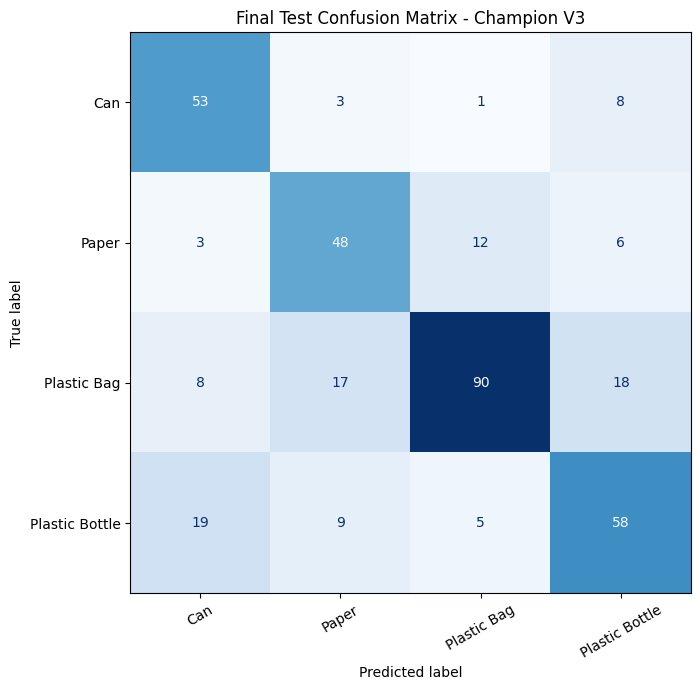


FINAL TEST RESULTS - APPROVED CHAMPION V3
Test Samples:       358
Test Loss:          0.7757
Test Accuracy:      0.6955 (69.55%)
Test Macro-F1:      0.6904 (69.04%)

Saved files:
Report: E:\ModelForge-AI\reports\final_test_report.json
Confusion Matrix: E:\ModelForge-AI\reports\final_confusion_matrix.png
Confusion Matrix CSV: E:\ModelForge-AI\reports\final_confusion_matrix.csv

Final test evaluation logged to MLflow.


In [52]:

# ============================================================
# CELL 46: FINAL TEST EVALUATION - PROMOTED CHAMPION V3
# ============================================================

import json
import torch
import numpy as np
import pandas as pd
import mlflow
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ACTIVE_CHAMPION_PATH = CHAMPION_DIR / "champion.pth"

FINAL_REPORT_PATH = REPORTS_DIR / "final_test_report.json"
FINAL_CM_PATH = REPORTS_DIR / "final_confusion_matrix.png"
FINAL_CM_CSV_PATH = REPORTS_DIR / "final_confusion_matrix.csv"

print("=" * 65)
print("FINAL TEST EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD APPROVED CHAMPION
# ------------------------------------------------------------

approved_checkpoint = torch.load(
    ACTIVE_CHAMPION_PATH,
    map_location=DEVICE,
    weights_only=False
)

assert approved_checkpoint["model_version"] == "challenger_v3"
assert approved_checkpoint["dataset_fingerprint"] == champion_checkpoint["dataset_fingerprint"]
assert list(approved_checkpoint["class_names"]) == list(MODEL_CLASS_NAMES)

final_model = create_mobilenet(NUM_CLASSES)

final_model.load_state_dict(
    approved_checkpoint["model_state_dict"]
)

final_model = final_model.to(DEVICE)
final_model.eval()

print("Approved model:", approved_checkpoint["model_version"])
print("Model loaded successfully.")

# ------------------------------------------------------------
# 3. EVALUATE ON TEST SET
# ------------------------------------------------------------

test_results = evaluate_model(
    final_model,
    test_loader,
    criterion
)

test_loss = float(test_results["loss"])
test_accuracy = float(test_results["accuracy"])
test_macro_f1 = float(test_results["macro_f1"])

y_true = np.asarray(test_results["labels"], dtype=int)
y_pred = np.asarray(test_results["predictions"], dtype=int)

assert len(y_true) == len(y_pred)
assert len(y_true) > 0

assert all(
    np.isfinite(value)
    for value in [test_loss, test_accuracy, test_macro_f1]
)

# ------------------------------------------------------------
# 4. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=MODEL_CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=MODEL_CLASS_NAMES,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("-" * 65)
print(report_text)

# ------------------------------------------------------------
# 5. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

cm_df = pd.DataFrame(
    cm,
    index=MODEL_CLASS_NAMES,
    columns=MODEL_CLASS_NAMES
)

cm_df.to_csv(FINAL_CM_CSV_PATH)

fig, ax = plt.subplots(figsize=(9, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=MODEL_CLASS_NAMES
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
    colorbar=False
)

ax.set_title("Final Test Confusion Matrix - Champion V3")
plt.tight_layout()

plt.savefig(FINAL_CM_PATH, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. SAVE FINAL REPORT
# ------------------------------------------------------------

final_report = {
    "approved_model": approved_checkpoint["model_version"],
    "training_run_id": approved_checkpoint["training_run_id"],
    "dataset_fingerprint": approved_checkpoint["dataset_fingerprint"],
    "evaluation_split": "test",
    "test_samples": int(len(y_true)),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "class_names": MODEL_CLASS_NAMES,
    "classification_report": report,
    "confusion_matrix": cm.tolist()
}

with open(FINAL_REPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(final_report, f, indent=4, allow_nan=False)

# ------------------------------------------------------------
# 7. LOG FINAL EVALUATION TO MLFLOW
# ------------------------------------------------------------

with mlflow.start_run(
    run_name="champion-v3-final-test-evaluation"
):

    mlflow.log_params({
        "evaluated_model": approved_checkpoint["model_version"],
        "evaluation_split": "test",
        "architecture": approved_checkpoint["architecture"],
        "num_classes": NUM_CLASSES,
        "test_samples": len(y_true),
        "dataset_fingerprint": approved_checkpoint["dataset_fingerprint"]
    })

    mlflow.log_metrics({
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_macro_f1": test_macro_f1
    })

    mlflow.set_tags({
        "model_role": "approved_champion",
        "evaluation_type": "final_test",
        "promotion_status": "promoted"
    })

    mlflow.log_artifact(str(FINAL_REPORT_PATH))
    mlflow.log_artifact(str(FINAL_CM_PATH))
    mlflow.log_artifact(str(FINAL_CM_CSV_PATH))

# ------------------------------------------------------------
# 8. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL TEST RESULTS - APPROVED CHAMPION V3")
print("=" * 65)

print(f"Test Samples:       {len(y_true)}")
print(f"Test Loss:          {test_loss:.4f}")
print(f"Test Accuracy:      {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Test Macro-F1:      {test_macro_f1:.4f} ({test_macro_f1 * 100:.2f}%)")

print("\nSaved files:")
print("Report:", FINAL_REPORT_PATH)
print("Confusion Matrix:", FINAL_CM_PATH)
print("Confusion Matrix CSV:", FINAL_CM_CSV_PATH)

print("\nFinal test evaluation logged to MLflow.")
print("=" * 65)


In [53]:

# ============================================================
# CELL 47: MLFLOW INFERENCE TRACING COMPATIBILITY CHECK
# ============================================================

import mlflow
import inspect

print("=" * 60)
print("MLFLOW ENVIRONMENT CHECK")
print("=" * 60)

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

print(
    "mlflow.trace available:",
    hasattr(mlflow, "trace")
)

print(
    "mlflow.start_span available:",
    hasattr(mlflow, "start_span")
)

print(
    "mlflow.log_artifact available:",
    hasattr(mlflow, "log_artifact")
)

print(
    "Active experiment:",
    mlflow.get_experiment_by_name("ModelForge-AI").name
)

print("=" * 60)


MLFLOW ENVIRONMENT CHECK
MLflow version: 3.18.0
Tracking URI: sqlite:///E:/ModelForge-AI/mlflow.db
mlflow.trace available: True
mlflow.start_span available: True
mlflow.log_artifact available: True
Active experiment: ModelForge-AI


Build the traced inference function

In [54]:

# ============================================================
# CELL 48: MLFLOW TRACED INFERENCE FUNCTION
# ============================================================

import torch
import mlflow
import numpy as np

# Use the existing project experiment
mlflow.set_experiment("ModelForge-AI")

# Confirm approved model is loaded
assert approved_checkpoint["model_version"] == "challenger_v3"

final_model.eval()

@torch.inference_mode()
def predict_with_trace(image_tensor, sample_id="sample"):

    # Every invocation creates an inspectable MLflow trace.
    with mlflow.start_span(
        name="waste_classifier_inference",
        span_type="CHAIN"
    ) as span:

        # Record metadata only: never record raw image tensors.
        input_metadata = {
            "sample_id": str(sample_id),
            "input_type": type(image_tensor).__name__,
            "input_shape": (
                list(image_tensor.shape)
                if isinstance(image_tensor, torch.Tensor)
                else None
            ),
            "model_version": "challenger_v3"
        }

        span.set_inputs(input_metadata)

        span.set_attribute(
            "model_version",
            "challenger_v3"
        )

        # Validate input
        if not isinstance(image_tensor, torch.Tensor):
            raise TypeError(
                "Input must be a PyTorch tensor."
            )

        if image_tensor.ndim != 3:
            raise ValueError(
                "Expected image shape [C, H, W]."
            )

        if image_tensor.shape[0] != 3:
            raise ValueError(
                "Expected a 3-channel RGB image."
            )

        if not torch.isfinite(image_tensor).all().item():
            raise ValueError(
                "Input tensor contains NaN or infinite values."
            )

        # Run inference
        input_batch = image_tensor.unsqueeze(0).to(DEVICE)

        logits = final_model(input_batch)

        probabilities = torch.softmax(logits, dim=1)

        confidence, predicted_index = torch.max(
            probabilities,
            dim=1
        )

        predicted_index = int(predicted_index.item())
        confidence = float(confidence.item())

        prediction = {
            "sample_id": str(sample_id),
            "predicted_class": MODEL_CLASS_NAMES[predicted_index],
            "predicted_class_id": predicted_index,
            "confidence": confidence,
            "model_version": "challenger_v3"
        }

        # Record prediction output in the trace
        span.set_outputs(prediction)

        span.set_attribute(
            "predicted_class",
            prediction["predicted_class"]
        )

        span.set_attribute(
            "confidence",
            confidence
        )

        return prediction


print("Traced inference function created successfully.")
print("Model:", approved_checkpoint["model_version"])
print("MLflow version:", mlflow.__version__)


Traced inference function created successfully.
Model: challenger_v3
MLflow version: 3.18.0


Generate 10 successful traces and 1 error trace

In [55]:

# ============================================================
# CELL 49: GENERATE 10 SUCCESSFUL + 1 ERROR TRACE
# ============================================================

import mlflow

TRACE_RESULTS = []

print("=" * 65)
print("GENERATING MLFLOW INFERENCE TRACES")
print("=" * 65)

# ------------------------------------------------------------
# 1. GENERATE 10 SUCCESSFUL INFERENCE TRACES
# ------------------------------------------------------------

assert len(test_dataset) >= 10, "Test dataset has fewer than 10 images."

for index in range(10):

    image_tensor, _ = test_dataset[index]

    result = predict_with_trace(
        image_tensor,
        sample_id=f"test_sample_{index + 1:02d}"
    )

    TRACE_RESULTS.append(result)

    print(
        f"{index + 1:02d}. "
        f"{result['sample_id']} | "
        f"Prediction: {result['predicted_class']} | "
        f"Confidence: {result['confidence']:.4f}"
    )

# ------------------------------------------------------------
# 2. GENERATE ONE INTENTIONAL INVALID-INPUT TRACE
# ------------------------------------------------------------

print("\nGenerating intentional invalid-input trace...")

try:

    predict_with_trace(
        None,
        sample_id="invalid_test_input"
    )

except (TypeError, ValueError) as error:

    print("Expected inference error captured:")
    print(type(error).__name__ + ":", error)

# ------------------------------------------------------------
# 3. RETRIEVE TRACES FROM MLFLOW
# ------------------------------------------------------------

experiment = mlflow.get_experiment_by_name("ModelForge-AI")

traces = mlflow.search_traces(
    experiment_ids=[experiment.experiment_id],
    max_results=50,
    return_type="list",
    flush=True
)

print("\n" + "=" * 65)
print("MLFLOW TRACE VERIFICATION")
print("=" * 65)

print("Total traces retrieved:", len(traces))

for trace in traces[:20]:

    trace_info = trace.info

    print(
        "Trace ID:", trace_info.trace_id,
        "| Status:", trace_info.status,
        "| Start:", trace_info.timestamp_ms
    )

# ------------------------------------------------------------
# 4. CHECK TRACE COUNT
# ------------------------------------------------------------

successful_inferences = len(TRACE_RESULTS)

print("\nSuccessful inference calls:", successful_inferences)
print("Intentional invalid-input call: 1")
print("Expected new traces: 11")

if len(traces) >= 11:
    print("\nTrace count requirement appears satisfied.")
else:
    print(
        "\nWARNING: Fewer than 11 traces retrieved. "
        "Check the MLflow Traces tab and experiment."
    )

print("=" * 65)


GENERATING MLFLOW INFERENCE TRACES
01. test_sample_01 | Prediction: Can | Confidence: 0.9037
02. test_sample_02 | Prediction: Can | Confidence: 0.9987
03. test_sample_03 | Prediction: Plastic Bottle | Confidence: 0.8998
04. test_sample_04 | Prediction: Can | Confidence: 0.9903
05. test_sample_05 | Prediction: Can | Confidence: 0.9991
06. test_sample_06 | Prediction: Can | Confidence: 0.9841
07. test_sample_07 | Prediction: Plastic Bottle | Confidence: 0.6638
08. test_sample_08 | Prediction: Plastic Bottle | Confidence: 0.5031
09. test_sample_09 | Prediction: Can | Confidence: 0.9999
10. test_sample_10 | Prediction: Can | Confidence: 0.9535

Generating intentional invalid-input trace...
Expected inference error captured:
TypeError: Input must be a PyTorch tensor.


C:\Users\faiza\AppData\Local\Temp\ipykernel_18772\2751578936.py:61: FutureWarning: Parameter 'experiment_ids' is deprecated. Please use 'locations' instead.
  traces = mlflow.search_traces(



MLFLOW TRACE VERIFICATION
Total traces retrieved: 11
Trace ID: tr-89463e85759cde66bacfb3d00b1f9163 | Status: TraceStatus.ERROR | Start: 1794907024160
Trace ID: tr-9a8dca03580d7b71d8f564135be6128e | Status: TraceStatus.OK | Start: 1794907024144
Trace ID: tr-17be31111a2a73ed562b0f79c37459ee | Status: TraceStatus.OK | Start: 1794907024117
Trace ID: tr-27cd813047229389571aa8766c307511 | Status: TraceStatus.OK | Start: 1794907024083
Trace ID: tr-ce4a2bbdc241330b01a9e71fde8a774b | Status: TraceStatus.OK | Start: 1794907024024
Trace ID: tr-96da1dac72ff5d2a386ecbe06b65a6a4 | Status: TraceStatus.OK | Start: 1794907023914
Trace ID: tr-a65ed389b74d0fb132e706298fadc1a6 | Status: TraceStatus.OK | Start: 1794907023879
Trace ID: tr-815ef6d13b8faa1837f8a88b17fc695a | Status: TraceStatus.OK | Start: 1794907023844
Trace ID: tr-6c031199972a846916419f828b9d2434 | Status: TraceStatus.OK | Start: 1794907023811
Trace ID: tr-ad3c2d6d1a3d1fa7bc8960a923b8c1e9 | Status: TraceStatus.OK | Start: 1794907023770
Tra

Generate the complete project implementation

In [56]:

# ============================================================
# MODELFORGE AI - COMPLETE PROJECT IMPLEMENTATION
# Generates application, inference engine, tests, CI/CD,
# model release, SHA-256 manifest, rollback and documentation.
# ============================================================

from pathlib import Path
from datetime import datetime
import shutil

ROOT = Path(r"E:\ModelForge-AI")

assert ROOT.exists(), f"Project folder not found: {ROOT}"

STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
BACKUP_DIR = ROOT / "reports" / "codegen_backups" / STAMP
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

FILES = {}

# ------------------------------------------------------------
# 1. INFERENCE ENGINE
# ------------------------------------------------------------

FILES["src/modelforge/__init__.py"] = r'''
"""ModelForge AI waste classification package."""
'''

FILES["src/modelforge/inference.py"] = r'''
from pathlib import Path

import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def create_model(num_classes: int):
    model = models.mobilenet_v3_small(weights=None)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, num_classes)
    return model


def get_preprocessing(image_size=224):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )
    ])


def load_approved_model(checkpoint_path, device=None):
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Approved model checkpoint not found: {checkpoint_path}"
        )

    device = device or torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    if checkpoint.get("architecture") != "MobileNetV3-Small":
        raise ValueError("Unexpected model architecture.")

    class_names = checkpoint.get("class_names")
    class_to_idx = checkpoint.get("class_to_idx")

    if not class_names or not class_to_idx:
        raise ValueError("Checkpoint class mapping is missing.")

    if len(class_names) != len(class_to_idx):
        raise ValueError("Invalid checkpoint class mapping.")

    model = create_model(len(class_names))

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    return model, checkpoint, device


def preprocess_image(image, image_size=224):
    if not isinstance(image, Image.Image):
        raise TypeError("Expected a PIL image.")

    image = image.convert("RGB")

    tensor = get_preprocessing(image_size)(image)

    if tensor.shape != (3, image_size, image_size):
        raise ValueError("Unexpected preprocessed image shape.")

    if not torch.isfinite(tensor).all():
        raise ValueError("Preprocessed image contains invalid values.")

    return tensor


@torch.inference_mode()
def predict_image(image, model, checkpoint, device):
    if not isinstance(image, Image.Image):
        raise TypeError("Input must be a PIL image.")

    image_size = int(checkpoint.get("image_size", 224))
    tensor = preprocess_image(image, image_size)

    batch = tensor.unsqueeze(0).to(device)
    logits = model(batch)

    if not torch.isfinite(logits).all():
        raise ValueError("Model produced invalid output.")

    probabilities = torch.softmax(logits, dim=1)

    confidence, predicted_index = probabilities.max(dim=1)

    predicted_index = int(predicted_index.item())
    confidence = float(confidence.item())

    class_names = checkpoint["class_names"]

    return {
        "predicted_class": class_names[predicted_index],
        "predicted_class_id": predicted_index,
        "confidence": confidence,
        "probabilities": {
            class_names[i]: float(probabilities[0, i].item())
            for i in range(len(class_names))
        },
        "model_version": checkpoint.get("model_version", "unknown")
    }
'''

# ------------------------------------------------------------
# 2. VIDEO PROCESSING ENGINE
# ------------------------------------------------------------

FILES["src/modelforge/video.py"] = r'''
from pathlib import Path
import cv2
import pandas as pd

from PIL import Image

from .inference import predict_image


SUPPORTED_VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov"}


def calculate_frame_stride(fps, interval_seconds):
    if fps <= 0:
        raise ValueError("Video FPS must be greater than zero.")

    if interval_seconds <= 0:
        raise ValueError("Frame interval must be greater than zero.")

    return max(1, round(fps * interval_seconds))


def process_video(
    input_path,
    output_path,
    model,
    checkpoint,
    device,
    interval_seconds=1.0
):
    input_path = Path(input_path)
    output_path = Path(output_path)

    if input_path.suffix.lower() not in SUPPORTED_VIDEO_EXTENSIONS:
        raise ValueError("Unsupported video format.")

    if not input_path.exists() or input_path.stat().st_size == 0:
        raise ValueError("Video file is missing or empty.")

    if interval_seconds <= 0:
        raise ValueError("Interval must be greater than zero.")

    capture = cv2.VideoCapture(str(input_path))

    if not capture.isOpened():
        raise ValueError("Unable to open uploaded video.")

    fps = float(capture.get(cv2.CAP_PROP_FPS))
    frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0 or frame_count <= 0:
        capture.release()
        raise ValueError("Invalid video metadata.")

    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))

    stride = calculate_frame_stride(fps, interval_seconds)

    output_path.parent.mkdir(parents=True, exist_ok=True)

    output_fps = 1.0 / interval_seconds

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        output_fps,
        (width, height)
    )

    if not writer.isOpened():
        capture.release()
        raise RuntimeError("Unable to create annotated output video.")

    records = []
    frame_index = 0
    sampled_index = 0

    try:
        while True:
            success, frame = capture.read()

            if not success:
                break

            if frame_index % stride == 0:

                timestamp = frame_index / fps

                rgb_frame = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                pil_image = Image.fromarray(rgb_frame)

                result = predict_image(
                    pil_image,
                    model,
                    checkpoint,
                    device
                )

                label = result["predicted_class"]
                confidence = result["confidence"]

                text = f"{label} | {confidence:.1%}"

                cv2.rectangle(
                    frame,
                    (8, 8),
                    (min(width - 8, 500), 58),
                    (0, 0, 0),
                    -1
                )

                cv2.putText(
                    frame,
                    text,
                    (18, 42),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (255, 255, 255),
                    2,
                    cv2.LINE_AA
                )

                writer.write(frame)

                records.append({
                    "sampled_frame": sampled_index,
                    "source_frame": frame_index,
                    "timestamp_seconds": round(timestamp, 3),
                    "predicted_class": label,
                    "confidence": confidence
                })

                sampled_index += 1

            frame_index += 1

    finally:
        capture.release()
        writer.release()

    if not records:
        raise RuntimeError("No video frames could be processed.")

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise RuntimeError("Annotated video output was not created.")

    results_df = pd.DataFrame(records)

    distribution = (
        results_df["predicted_class"]
        .value_counts()
        .to_dict()
    )

    summary = {
        "total_source_frames": frame_count,
        "sampled_frames": len(results_df),
        "source_fps": fps,
        "video_duration_seconds": frame_count / fps,
        "frame_interval_seconds": interval_seconds,
        "majority_predicted_class": results_df[
            "predicted_class"
        ].value_counts().idxmax(),
        "mean_confidence": float(
            results_df["confidence"].mean()
        ),
        "class_distribution": distribution
    }

    return results_df, summary
'''

# ------------------------------------------------------------
# 3. STREAMLIT APPLICATION
# ------------------------------------------------------------

FILES["streamlit_app.py"] = r'''
import os
import sys
import tempfile
from pathlib import Path

import streamlit as st
import pandas as pd
import torch

from PIL import Image

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from modelforge.inference import (
    load_approved_model,
    predict_image
)

from modelforge.video import process_video


MODEL_PATH = Path(
    os.getenv(
        "MODEL_CHECKPOINT",
        str(ROOT / "models" / "champion" / "champion.pth")
    )
)


st.set_page_config(
    page_title="ModelForge AI",
    page_icon="♻️",
    layout="wide"
)


st.title("♻️ ModelForge AI")
st.subheader("AI-Based Waste Image and Video Classification")

st.markdown(
    """
    Classify waste images and sampled video frames using the
    approved MobileNetV3-Small Champion model.

    **Classes:** Can · Paper · Plastic Bag · Plastic Bottle
    """
)


@st.cache_resource
def get_model(path_string):
    return load_approved_model(path_string)


try:
    model, checkpoint, device = get_model(str(MODEL_PATH))
except Exception as error:
    st.error(f"Model loading failed: {error}")
    st.stop()


st.success(
    f"Loaded approved model: "
    f"{checkpoint.get('model_version', 'unknown')}"
)

st.caption(f"Device: {device}")


mode = st.sidebar.radio(
    "Choose input type",
    ["Image Classification", "Video Classification"]
)


# ============================================================
# IMAGE CLASSIFICATION
# ============================================================

if mode == "Image Classification":

    st.header("Image Classification")

    uploaded_image = st.file_uploader(
        "Upload a waste image",
        type=["jpg", "jpeg", "png"],
        key="image_upload"
    )

    if uploaded_image is not None:

        try:
            image = Image.open(uploaded_image).convert("RGB")

            st.image(
                image,
                caption="Uploaded image",
                use_container_width=True
            )

            if st.button("Classify Image", type="primary"):

                with st.spinner("Running MobileNetV3 inference..."):

                    result = predict_image(
                        image,
                        model,
                        checkpoint,
                        device
                    )

                st.subheader("Prediction")

                col1, col2 = st.columns(2)

                col1.metric(
                    "Predicted class",
                    result["predicted_class"]
                )

                col2.metric(
                    "Confidence",
                    f"{result['confidence']:.2%}"
                )

                probability_df = pd.DataFrame({
                    "Class": list(result["probabilities"].keys()),
                    "Probability": list(result["probabilities"].values())
                })

                st.subheader("Class probabilities")

                st.bar_chart(
                    probability_df.set_index("Class")
                )

                st.dataframe(
                    probability_df,
                    use_container_width=True
                )

        except Exception as error:
            st.error(f"Image processing failed: {error}")


# ============================================================
# VIDEO CLASSIFICATION
# ============================================================

elif mode == "Video Classification":

    st.header("Video Frame Classification")

    st.info(
        "The model classifies sampled frames independently. "
        "It does not detect object locations or draw bounding boxes. "
        "The annotated output is a sampled-frame preview."
    )

    uploaded_video = st.file_uploader(
        "Upload a video",
        type=["mp4", "avi", "mov"],
        key="video_upload"
    )

    interval = st.slider(
        "Seconds between sampled frames",
        min_value=0.5,
        max_value=5.0,
        value=1.0,
        step=0.5
    )

    if uploaded_video is not None:

        st.video(uploaded_video)

        if st.button("Process Video", type="primary"):

            with tempfile.TemporaryDirectory() as temp_dir:

                temp_dir = Path(temp_dir)

                input_path = temp_dir / (
                    "uploaded" + Path(uploaded_video.name).suffix.lower()
                )

                output_path = temp_dir / "annotated_preview.mp4"

                input_path.write_bytes(uploaded_video.getvalue())

                try:

                    progress = st.progress(0)
                    status = st.empty()

                    status.info(
                        "Processing sampled frames. "
                        "Please wait..."
                    )

                    results_df, summary = process_video(
                        input_path=input_path,
                        output_path=output_path,
                        model=model,
                        checkpoint=checkpoint,
                        device=device,
                        interval_seconds=interval
                    )

                    progress.progress(100)
                    status.success("Video processing completed.")

                    st.subheader("Video summary")

                    col1, col2, col3 = st.columns(3)

                    col1.metric(
                        "Sampled frames",
                        summary["sampled_frames"]
                    )

                    col2.metric(
                        "Majority class",
                        summary["majority_predicted_class"]
                    )

                    col3.metric(
                        "Mean confidence",
                        f"{summary['mean_confidence']:.2%}"
                    )

                    st.subheader("Frame-level results")

                    st.dataframe(
                        results_df,
                        use_container_width=True
                    )

                    st.subheader("Class distribution")

                    distribution_df = pd.DataFrame(
                        list(summary["class_distribution"].items()),
                        columns=["Class", "Frame count"]
                    )

                    st.bar_chart(
                        distribution_df.set_index("Class")
                    )

                    st.subheader("Annotated sampled-frame video")

                    output_bytes = output_path.read_bytes()

                    st.video(output_bytes)

                    st.download_button(
                        "Download annotated video",
                        data=output_bytes,
                        file_name="modelforge_annotated_preview.mp4",
                        mime="video/mp4"
                    )

                    csv_bytes = results_df.to_csv(
                        index=False
                    ).encode("utf-8")

                    st.download_button(
                        "Download frame predictions CSV",
                        data=csv_bytes,
                        file_name="video_frame_predictions.csv",
                        mime="text/csv"
                    )

                except Exception as error:
                    st.error(f"Video processing failed: {error}")


st.divider()

st.caption(
    "ModelForge AI | MobileNetV3-Small | "
    "Approved Champion V3 | Image and sampled-video classification"
)
'''

# ------------------------------------------------------------
# 4. AUTOMATED TESTS
# ------------------------------------------------------------

FILES["tests/test_inference.py"] = r'''
import sys
from pathlib import Path

import pytest
import torch
from PIL import Image

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from modelforge.inference import (
    preprocess_image,
    create_model,
    load_approved_model,
    predict_image
)


def test_preprocessing_output_shape():

    image = Image.new("RGB", (320, 240), color="white")

    tensor = preprocess_image(image)

    assert tensor.shape == (3, 224, 224)
    assert torch.isfinite(tensor).all()


def test_preprocessing_converts_rgb():

    image = Image.new("L", (200, 200), color=128)

    tensor = preprocess_image(image)

    assert tensor.shape[0] == 3


def test_invalid_image_input():

    with pytest.raises(TypeError):
        preprocess_image("not-an-image")


def test_model_output_shape():

    model = create_model(4)
    model.eval()

    with torch.no_grad():
        output = model(torch.randn(2, 3, 224, 224))

    assert output.shape == (2, 4)
    assert torch.isfinite(output).all()


def test_approved_checkpoint_integration():

    checkpoint_path = (
        ROOT / "models" / "champion" / "champion.pth"
    )

    if not checkpoint_path.exists():
        pytest.skip("Approved checkpoint not present in checkout.")

    model, checkpoint, device = load_approved_model(checkpoint_path)

    assert checkpoint["model_version"] == "challenger_v3"
    assert len(checkpoint["class_names"]) == 4

    image = Image.new("RGB", (224, 224), color="white")

    result = predict_image(
        image,
        model,
        checkpoint,
        device
    )

    assert result["predicted_class"] in checkpoint["class_names"]
    assert 0 <= result["confidence"] <= 1
    assert len(result["probabilities"]) == 4
'''


FILES["tests/test_video.py"] = r'''
import sys
from pathlib import Path

import pytest

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from modelforge.video import calculate_frame_stride


def test_frame_stride_one_second():

    assert calculate_frame_stride(30, 1.0) == 30


def test_frame_stride_half_second():

    assert calculate_frame_stride(30, 0.5) == 15


def test_frame_stride_minimum_one():

    assert calculate_frame_stride(1, 0.1) == 1


def test_invalid_fps():

    with pytest.raises(ValueError):
        calculate_frame_stride(0, 1)


def test_invalid_interval():

    with pytest.raises(ValueError):
        calculate_frame_stride(30, 0)
'''


FILES["tests/conftest.py"] = r'''
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]

sys.path.insert(0, str(ROOT / "src"))
'''

# ------------------------------------------------------------
# 5. RELEASE MANIFEST GENERATOR
# ------------------------------------------------------------

FILES["scripts/create_release_manifest.py"] = r'''
from pathlib import Path
import hashlib
import json
from datetime import datetime, timezone

ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = ROOT / "models" / "champion" / "champion.pth"
OUTPUT_PATH = ROOT / "models" / "champion" / "release_manifest.json"


def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

import torch

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

manifest = {
    "release_version": checkpoint.get("model_version"),
    "architecture": checkpoint.get("architecture"),
    "class_names": checkpoint.get("class_names"),
    "dataset_fingerprint": checkpoint.get("dataset_fingerprint"),
    "training_run_id": checkpoint.get("training_run_id"),
    "sha256": sha256_file(MODEL_PATH),
    "model_file": MODEL_PATH.name,
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

OUTPUT_PATH.write_text(
    json.dumps(manifest, indent=4),
    encoding="utf-8"
)

print(json.dumps(manifest, indent=4))
print("Manifest saved:", OUTPUT_PATH)
'''


# ------------------------------------------------------------
# 6. ROLLBACK SCRIPT
# ------------------------------------------------------------

FILES["scripts/rollback_champion.py"] = r'''
from pathlib import Path
import shutil
import sys
from datetime import datetime

ROOT = Path(__file__).resolve().parents[1]

CHAMPION_DIR = ROOT / "models" / "champion"
ACTIVE = CHAMPION_DIR / "champion.pth"

if len(sys.argv) > 1:
    backup = Path(sys.argv[1])
else:
    backups = sorted(
        CHAMPION_DIR.glob("champion_backup_*.pth"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    if not backups:
        raise FileNotFoundError("No Champion backup found.")

    backup = backups[0]

if not backup.exists():
    raise FileNotFoundError(backup)

if ACTIVE.exists():

    snapshot = CHAMPION_DIR / (
        "champion_before_rollback_"
        + datetime.now().strftime("%Y%m%d_%H%M%S")
        + ".pth"
    )

    shutil.copy2(ACTIVE, snapshot)
    print("Current Champion snapshot:", snapshot)

shutil.copy2(backup, ACTIVE)

print("Rollback completed.")
print("Restored model:", backup)
print("Active model:", ACTIVE)
'''


# ------------------------------------------------------------
# 7. CI REQUIREMENTS
# ------------------------------------------------------------

FILES["requirements.txt"] = r'''
torch
torchvision
streamlit
opencv-python-headless
Pillow
pandas
numpy
mlflow
scikit-learn
pytest
'''

FILES["requirements-ci.txt"] = r'''
torch
torchvision
Pillow
numpy
pandas
opencv-python-headless
pytest
'''

# ------------------------------------------------------------
# 8. GITHUB ACTIONS CI WORKFLOW
# ------------------------------------------------------------

FILES[".github/workflows/ci.yml"] = r'''
name: ModelForge AI - Continuous Integration

on:
  push:
    branches: [main, master, develop]
  pull_request:
    branches: [main, master]

permissions:
  contents: read

jobs:
  test:
    name: Install, Test and Validate
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4
        with:
          lfs: true

      - name: Setup Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements-ci.txt

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements-ci.txt

      - name: Validate project files
        run: |
          test -f streamlit_app.py
          test -f src/modelforge/inference.py
          test -f src/modelforge/video.py
          test -f models/champion/champion.pth

      - name: Run automated tests
        run: |
          pytest -v tests --junitxml=test-results.xml

      - name: Upload test results
        if: always()
        uses: actions/upload-artifact@v4
        with:
          name: modelforge-test-results
          path: test-results.xml
'''


# ------------------------------------------------------------
# 9. GITHUB ACTIONS MODEL RELEASE WORKFLOW
# ------------------------------------------------------------

FILES[".github/workflows/model-release.yml"] = r'''
name: ModelForge AI - Model Release

on:
  push:
    tags:
      - "v*"

permissions:
  contents: write

jobs:
  release:
    name: Validate and Release Champion
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4
        with:
          lfs: true

      - name: Setup Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install torch torchvision

      - name: Verify approved model exists
        run: |
          test -f models/champion/champion.pth

      - name: Generate SHA-256 release manifest
        run: |
          python scripts/create_release_manifest.py

      - name: Verify manifest
        run: |
          python -c "import json; d=json.load(open('models/champion/release_manifest.json')); assert len(d['sha256']) == 64"

      - name: Create GitHub release
        uses: softprops/action-gh-release@v2
        with:
          name: ModelForge AI ${{ github.ref_name }}
          generate_release_notes: true
          files: |
            models/champion/champion.pth
            models/champion/release_manifest.json
'''


# ------------------------------------------------------------
# 10. GITIGNORE
# ------------------------------------------------------------

FILES[".gitignore"] = r'''
# Python
__pycache__/
*.py[cod]
.pytest_cache/
.venv/
venv/

# Jupyter
.ipynb_checkpoints/

# MLflow local data
mlruns/
mlartifacts/
mlflow.db
mlflow.db-shm
mlflow.db-wal

# Dataset - do not upload raw or processed images
data/raw/
data/processed/

# Temporary output
temp/
tmp/
*.tmp
*.log

# OS
.DS_Store
Thumbs.db
desktop.ini

# Backups
reports/codegen_backups/
'''

# ------------------------------------------------------------
# 11. STREAMLIT CONFIG
# ------------------------------------------------------------

FILES[".streamlit/config.toml"] = r'''
[server]
maxUploadSize = 200
headless = true

[browser]
gatherUsageStats = false
'''


# ------------------------------------------------------------
# 12. README
# ------------------------------------------------------------

FILES["README.md"] = r'''
# ModelForge AI

**Champion-Challenger Transfer Learning with MLflow and GitHub Actions**

ModelForge AI is a waste image and sampled-video classification system built
with MobileNetV3-Small, PyTorch, MLflow and Streamlit.

## Supported classes

- Can
- Paper
- Plastic Bag
- Plastic Bottle

## Model

The approved model is Challenger V3, promoted after validation-based
Champion-Challenger comparison.

Architecture: MobileNetV3-Small

Input size: 224 x 224

Preprocessing: RGB, ImageNet normalization

The model predicts one class for an input image.

## Application features

- Single-image classification
- Video upload and sampled-frame classification
- Frame-level prediction timeline
- Confidence scores
- Class distribution
- Annotated sampled-frame video download
- CSV prediction report download

Video processing is frame-level classification. The application does not
perform object localization or bounding-box detection.

## Project structure

```text
ModelForge-AI/
├── .github/workflows/
│   ├── ci.yml
│   └── model-release.yml
├── .streamlit/
│   └── config.toml
├── models/
│   └── champion/
│       └── champion.pth
├── scripts/
│   ├── create_release_manifest.py
│   └── rollback_champion.py
├── src/modelforge/
│   ├── __init__.py
│   ├── inference.py
│   └── video.py
├── tests/
│   ├── conftest.py
│   ├── test_inference.py
│   └── test_video.py
├── streamlit_app.py
├── requirements.txt
└── README.md
```

## Local setup

```powershell
cd E:\ModelForge-AI

python -m pip install -r requirements.txt

python -m pytest -v tests

python -m streamlit run streamlit_app.py
```

## MLflow

The training experiments, Champion-Challenger comparisons, promotion decision,
test evaluation and inference traces are tracked in MLflow.

## CI/CD

GitHub Actions runs automated tests on pushes and pull requests.

Pushing a version tag such as `v1.0.0` triggers model release validation,
SHA-256 manifest generation and GitHub Release creation.

## Model integrity

Generate the model manifest:

```powershell
python scripts/create_release_manifest.py
```

## Rollback

Restore the latest available Champion backup:

```powershell
python scripts/rollback_champion.py
```

Restore a particular backup:

```powershell
python scripts/rollback_champion.py models/champion/champion_backup_YYYYMMDD_HHMMSS.pth
```

## Dataset

The dataset is derived from the existing waste detection dataset.
The original train, validation and test split assignments were preserved.

Document the original public dataset source and its license before publication.

## Limitations

This is an image classifier, not an object detector. For video, it classifies
sampled frames independently. Small or multiple objects in a frame may reduce
prediction reliability.
'''

# ------------------------------------------------------------
# 13. PYTEST CONFIG
# ------------------------------------------------------------

FILES["pytest.ini"] = r'''
[pytest]
testpaths = tests
python_files = test_*.py
addopts = -ra
'''

# ------------------------------------------------------------
# 14. CREATE FILES WITH BACKUPS
# ------------------------------------------------------------

created = []
backed_up = []

for relative_path, content in FILES.items():

    target = ROOT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)

    if target.exists():

        backup_target = BACKUP_DIR / relative_path
        backup_target.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(target, backup_target)
        backed_up.append(str(relative_path))

    target.write_text(
        content.strip() + "\n",
        encoding="utf-8"
    )

    created.append(str(relative_path))


print("=" * 70)
print("MODELFORGE AI IMPLEMENTATION FILES GENERATED")
print("=" * 70)

print("\nFiles created:", len(created))

for item in created:
    print("[CREATED]", item)

print("\nExisting files backed up:", len(backed_up))

for item in backed_up:
    print("[BACKUP]", item)

print("\nBackup directory:", BACKUP_DIR)

print("\nApproved Champion checkpoint exists:",
      (ROOT / "models/champion/champion.pth").exists())

print("\n" + "=" * 70)
print("PROJECT IMPLEMENTATION GENERATION COMPLETED")
print("=" * 70)


MODELFORGE AI IMPLEMENTATION FILES GENERATED

Files created: 17
[CREATED] src/modelforge/__init__.py
[CREATED] src/modelforge/inference.py
[CREATED] src/modelforge/video.py
[CREATED] streamlit_app.py
[CREATED] tests/test_inference.py
[CREATED] tests/test_video.py
[CREATED] tests/conftest.py
[CREATED] scripts/create_release_manifest.py
[CREATED] scripts/rollback_champion.py
[CREATED] requirements.txt
[CREATED] requirements-ci.txt
[CREATED] .github/workflows/ci.yml
[CREATED] .github/workflows/model-release.yml
[CREATED] .gitignore
[CREATED] .streamlit/config.toml
[CREATED] README.md
[CREATED] pytest.ini

Existing files backed up: 0

Backup directory: E:\ModelForge-AI\reports\codegen_backups\20261117_142503

Approved Champion checkpoint exists: True

PROJECT IMPLEMENTATION GENERATION COMPLETED


Add candidate validation and protect model backups

In [57]:

# ============================================================
# ADDITIONAL CI/CD: CANDIDATE VALIDATION WORKFLOW
# ============================================================

from pathlib import Path

ROOT = Path(r"E:\ModelForge-AI")

candidate_validator = r'''
from pathlib import Path
import argparse
import json
import math
import torch

from modelforge.inference import create_model


parser = argparse.ArgumentParser()
parser.add_argument(
    "--candidate",
    default="models/candidates/challenger_candidate.pth"
)
args = parser.parse_args()

root = Path(__file__).resolve().parents[1]

active_path = root / "models/champion/champion.pth"
candidate_path = root / args.candidate

if not active_path.exists():
    raise FileNotFoundError(active_path)

if not candidate_path.exists():
    raise FileNotFoundError(candidate_path)

active = torch.load(active_path, map_location="cpu", weights_only=False)
candidate = torch.load(candidate_path, map_location="cpu", weights_only=False)

active_acc = float(active["validation_accuracy"])
candidate_acc = float(candidate["validation_accuracy"])

active_f1 = float(active["validation_macro_f1"])
candidate_f1 = float(candidate["validation_macro_f1"])

accuracy_gain = candidate_acc - active_acc
f1_change = candidate_f1 - active_f1

checks = {
    "finite_metrics": all(
        math.isfinite(x)
        for x in [active_acc, candidate_acc, active_f1, candidate_f1]
    ),
    "accuracy_improvement": accuracy_gain >= 0.005,
    "macro_f1_requirement": f1_change >= -0.01,
    "same_dataset": (
        active["dataset_fingerprint"]
        == candidate["dataset_fingerprint"]
    ),
    "same_class_names": (
        list(active["class_names"])
        == list(candidate["class_names"])
    ),
    "same_class_mapping": (
        active["class_to_idx"]
        == candidate["class_to_idx"]
    )
}

smoke_test = False

try:
    model = create_model(int(candidate["num_classes"]))
    model.load_state_dict(candidate["model_state_dict"])
    model.eval()

    with torch.inference_mode():
        output = model(torch.randn(1, 3, 224, 224))

    smoke_test = (
        output.shape == (1, int(candidate["num_classes"]))
        and torch.isfinite(output).all().item()
    )

except Exception as error:
    print("Smoke test failed:", error)

checks["checkpoint_smoke_test"] = smoke_test

result = {
    "candidate": str(candidate_path),
    "baseline": str(active_path),
    "accuracy_gain": accuracy_gain,
    "macro_f1_change": f1_change,
    "checks": checks,
    "decision": "ELIGIBLE_FOR_REVIEW" if all(checks.values()) else "REJECTED"
}

output_path = root / "candidate_validation_report.json"

output_path.write_text(
    json.dumps(result, indent=4),
    encoding="utf-8"
)

print(json.dumps(result, indent=4))

if not all(checks.values()):
    raise SystemExit("Candidate failed one or more validation gates.")

print("Candidate passed automated validation. Manual promotion review is still required.")
'''

candidate_workflow = r'''
name: ModelForge AI - Candidate Validation

on:
  workflow_dispatch:
    inputs:
      candidate_path:
        description: "Repository-relative challenger checkpoint path"
        required: true
        default: "models/candidates/challenger_candidate.pth"

permissions:
  contents: read

jobs:
  validate:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4
        with:
          lfs: true

      - name: Setup Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install torch torchvision

      - name: Validate challenger candidate
        run: |
          python scripts/validate_candidate.py --candidate "${{ inputs.candidate_path }}"

      - name: Upload candidate validation report
        if: always()
        uses: actions/upload-artifact@v4
        with:
          name: candidate-validation-report
          path: candidate_validation_report.json
          if-no-files-found: ignore
'''

def safe_write(relative, content):
    path = ROOT / relative
    path.parent.mkdir(parents=True, exist_ok=True)

    if path.exists():
        backup = ROOT / "reports" / "codegen_backups" / "additional" / relative
        backup.parent.mkdir(parents=True, exist_ok=True)
        import shutil
        shutil.copy2(path, backup)

    path.write_text(content.strip() + "\n", encoding="utf-8")
    print("[CREATED]", relative)


safe_write(
    "scripts/validate_candidate.py",
    candidate_validator
)

safe_write(
    ".github/workflows/candidate-validation.yml",
    candidate_workflow
)

# Keep the active model tracked, but exclude old model backups.
gitignore = ROOT / ".gitignore"
extra_ignores = """
# Keep only the active approved Champion in normal Git history
models/champion/champion_backup_*.pth
models/champion/champion_before_rollback_*.pth
reports/codegen_backups/
"""

existing = gitignore.read_text(encoding="utf-8") if gitignore.exists() else ""

if "champion_backup_*.pth" not in existing:
    with gitignore.open("a", encoding="utf-8") as f:
        f.write("\n" + extra_ignores)

print("\nCandidate validation workflow and backup exclusions are ready.")


[CREATED] scripts/validate_candidate.py
[CREATED] .github/workflows/candidate-validation.yml

Candidate validation workflow and backup exclusions are ready.


Small compatibility correction

In [59]:

from pathlib import Path

path = Path(r"E:\ModelForge-AI\scripts\validate_candidate.py")
content = path.read_text(encoding="utf-8")

old = "import torch\n\nfrom modelforge.inference import create_model"
new = (
    "import torch\nimport sys\n\n"
    "sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))\n\n"
    "from modelforge.inference import create_model"
)

if old in content:
    path.write_text(
        content.replace(old, new),
        encoding="utf-8"
    )
    print("Candidate validator import path fixed.")
else:
    print("Import path already fixed or expected text not found.")


Candidate validator import path fixed.
